# Atelier AI — Candidates and Features

## Objective

Define reproducible customer cohorts and purchase targets, establish reference recommendations, and prepare cutoff-safe candidates and features.

**Current milestone: 4.4b — full-cohort feature export.** Build, validate and store six million validation-cutoff candidate rows in bounded customer batches with seventeen model features. Historical training examples, fitted preprocessing and model training remain future work.

This notebook must run from a fresh kernel using the project virtual environment. It does not depend on variables from the previous notebooks.

## 1. Environment

Use the existing project readers and temporal helpers. Derive project paths from the installed package. Sections 4 and 5 scan transactions in bounded chunks: validation targets for the cohort, then pre-cutoff global popularity aggregates.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import atelier_ai

from atelier_ai.data_io import read_source_csv, read_source_chunks
from atelier_ai.temporal import interval_mask

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
RAW_DATA_DIRECTORY = PROJECT_ROOT / "data" / "raw" / "hm"

required_files = ["customers.csv", "articles.csv", "transactions_train.csv"]
missing_files = [name for name in required_files if not (RAW_DATA_DIRECTORY / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing source files: {missing_files}")

print("Python executable:", sys.executable)
print("Project root:", PROJECT_ROOT)
print("pandas version:", pd.__version__)
print("Required source files found.")

Python executable: /Users/oumar/Developer/portfolio/atelier-ai-project/.venv/bin/python
Project root: /Users/oumar/Developer/portfolio/atelier-ai-project
pandas version: 3.0.6
Required source files found.


## 2. Experiment Contract

### 2.1. Parameters and population policy

- Issue twelve distinct article recommendations at each cutoff.
- Observe distinct purchased articles during the next seven days.
- Start with a 180-day historical feature window. Shorter popularity windows are subsets of that history.
- The historical training pool established earlier is separate from this feature-window length.
- Plan one fixed cohort of 20,000 customer IDs selected using seeded stable hashing of IDs from the supplied customer table, independently of target purchases.
- This source-table cohort is a benchmark population; it does not establish that every account existed at each historical cutoff.
- Use all eligible source customers for global historical popularity aggregates, rather than restricting those aggregates to the evaluation cohort.
- Retain cohort customers without target purchases for recommendation generation. Exclude them only from the declared target-based metrics, reporting their excluded proportion.
- Report cases without history rather than silently removing them. Missing 180-day history does not necessarily mean a newly registered customer.
- Recompute histories, candidates and features strictly before each cutoff.
- Follow `docs/evaluation.md`: select using validation only; keep learned V1 parameters fixed for local test; do not inspect local test performance during development.

The 180-day window and 300-candidate budget are initial modelling choices, not measured optimal values.

In [2]:
VALIDATION_CUTOFF = pd.Timestamp("2020-09-09")
LOCAL_TEST_CUTOFF = pd.Timestamp("2020-09-16")

HORIZON_DAYS = 7
HISTORY_DAYS = 180
TOP_K = 12

COHORT_SIZE = 20_000
COHORT_SEED = 42
MAX_CANDIDATES = 300

### 2.2. Historical and target windows

Starts are inclusive; ends are exclusive. Validation-week transactions may become history at the test cutoff, but learned parameters remain fixed. Dates alone are displayed here; target extraction occurs only in section 4, for validation.

In [3]:
horizon = pd.Timedelta(days=HORIZON_DAYS)
history = pd.Timedelta(days=HISTORY_DAYS)

window_contract = pd.DataFrame([
    {
        "period": "validation_history",
        "start_inclusive": VALIDATION_CUTOFF - history,
        "end_exclusive": VALIDATION_CUTOFF,
    },
    {
        "period": "validation_target",
        "start_inclusive": VALIDATION_CUTOFF,
        "end_exclusive": VALIDATION_CUTOFF + horizon,
    },
    {
        "period": "local_test_history",
        "start_inclusive": LOCAL_TEST_CUTOFF - history,
        "end_exclusive": LOCAL_TEST_CUTOFF,
    },
    {
        "period": "local_test_target",
        "start_inclusive": LOCAL_TEST_CUTOFF,
        "end_exclusive": LOCAL_TEST_CUTOFF + horizon,
    },
])

window_contract["calendar_days"] = (
    window_contract["end_exclusive"]
    - window_contract["start_inclusive"]
).dt.days

window_contract

,period,start_inclusive,end_exclusive,calendar_days
0,validation_history,2020-03-13,2020-09-09,180
1,validation_target,2020-09-09,2020-09-16,7
2,local_test_history,2020-03-20,2020-09-16,180
3,local_test_target,2020-09-16,2020-09-23,7


### 2.3. Contract checks

These checks verify date arithmetic and declared sizes. They do not validate target extraction, candidate coverage or recommendation quality.

In [4]:
contract_checks = pd.Series(
    {
        "validation_target_ends_at_test_cutoff": (
            VALIDATION_CUTOFF + horizon == LOCAL_TEST_CUTOFF
        ),
        "history_windows_have_declared_length": (
            window_contract.loc[
                window_contract["period"].str.endswith("_history"),
                "calendar_days",
            ].eq(HISTORY_DAYS).all()
        ),
        "target_windows_have_declared_length": (
            window_contract.loc[
                window_contract["period"].str.endswith("_target"),
                "calendar_days",
            ].eq(HORIZON_DAYS).all()
        ),
        "candidate_budget_covers_top_k": MAX_CANDIDATES >= TOP_K > 0,
        "cohort_size_is_positive": COHORT_SIZE > 0,
    },
    name="passed",
)

if not contract_checks.all():
    failed = contract_checks.index[~contract_checks].tolist()
    raise ValueError(f"Experiment contract checks failed: {failed}")

contract_checks.to_frame()

,passed
validation_target_ends_at_test_cutoff,True
history_windows_have_declared_length,True
target_windows_have_declared_length,True
candidate_budget_covers_top_k,True
cohort_size_is_positive,True


## 3. Fixed Customer Cohort

### 3.1. Load the selection population

Read only customer IDs from the supplied customer table. Preserve string identifiers with the existing source reader. Do not filter on transactions, future purchases or available purchase history.

The cohort is a fixed computational benchmark drawn from the provided snapshot. The snapshot does not provide account creation dates, so historical account eligibility cannot be established. Selection does not guarantee representativeness in every customer segment.

In [5]:
from hashlib import sha256

source_customers = read_source_csv(
    RAW_DATA_DIRECTORY / "customers.csv",
    columns=["customer_id"],
)

print(f"Source customer IDs: {len(source_customers):,}")

Source customer IDs: 1,371,980


### 3.2. Define deterministic selection

Assign each unique customer ID a stable SHA-256 key derived from `seed:customer_id`, sort by that key and then by customer ID, and retain the first `size` rows without replacement. The secondary sort defines a tie-breaker.

Unlike taking the first source rows, selection is independent of source order. This uses the standard-library `hashlib`, rather than Python's session-dependent built-in `hash()`. The seed determines a reproducible ordering; it is neither a model parameter nor encryption. A fixed seed does not make the source snapshot historically complete.

This helper validates the input contract before selection. It stays in this notebook during exploration; extraction into the package can follow when its interface is stable.

In [6]:
def select_customer_cohort(
    customer_ids: pd.Series,
    *,
    size: int,
    seed: int,
) -> pd.DataFrame:
    """Select unique IDs by seeded SHA-256 ordering, independently of row order."""
    if not 0 < size <= len(customer_ids):
        raise ValueError("Cohort size must be positive and fit the source population.")
    if customer_ids.isna().any() or customer_ids.str.strip().eq("").any():
        raise ValueError("Customer IDs must not be missing or blank.")
    if not customer_ids.is_unique:
        raise ValueError("Customer IDs must be unique before cohort selection.")

    selection = customer_ids.rename("customer_id").reset_index(drop=True).to_frame()
    selection["selection_key"] = selection["customer_id"].map(
        lambda customer_id: sha256(
            f"{seed}:{customer_id}".encode("utf-8")
        ).hexdigest()
    )

    return (
        selection.sort_values(["selection_key", "customer_id"])
        .head(size)[["customer_id"]]
        .reset_index(drop=True)
    )

### 3.3. Select the benchmark customers

Use this same cohort for all validation methods and later for the local test. Changing the source, algorithm, seed or cohort size defines a different experiment population.

The cohort limits per-customer recommendation work. Global popularity statistics will still use all eligible historical source customers. No transaction data is read here.

In [7]:
cohort = select_customer_cohort(
    source_customers["customer_id"],
    size=COHORT_SIZE,
    seed=COHORT_SEED,
)

cohort_ids = pd.Index(cohort["customer_id"], name="customer_id")

cohort.head()

,customer_id
0,cbcb6cf21b3e0ada7e40afefec120a2d7bc92a2faf716a...
1,8f31c5d8dc7c540e48c79cbe0fada8a0d00441718ea833...
2,59dfa14ee76617564e4d0680c27e953a50b1104c96dd48...
3,968182f0b607e2b8fb45e2aa630eb4b02d4c75b06bc007...
4,746ec619478611fe9fa4a5feab21e5cf315921db427434...


### 3.4. Check size, membership and reproducibility

Check the full cohort against its source. Use a small, deliberately reordered fixture to test row-order invariance. Also verify that duplicate IDs are rejected rather than silently overrepresenting a customer.

These are input and reproducibility checks, not evidence of model quality or demographic representativeness.

In [8]:
example_ids = pd.Series(
    ["customer_c", "customer_a", "customer_e", "customer_b", "customer_d"],
    dtype="string",
)
example_cohort = select_customer_cohort(example_ids, size=3, seed=COHORT_SEED)
reordered_example_cohort = select_customer_cohort(
    example_ids.iloc[::-1], size=3, seed=COHORT_SEED
)

try:
    select_customer_cohort(
        pd.Series(["same_customer", "same_customer"], dtype="string"),
        size=1,
        seed=COHORT_SEED,
    )
except ValueError:
    duplicates_rejected = True
else:
    duplicates_rejected = False

cohort_checks = pd.Series(
    {
        "cohort_has_requested_size": len(cohort) == COHORT_SIZE,
        "cohort_ids_are_unique": cohort_ids.is_unique,
        "cohort_ids_are_non_missing": not cohort_ids.isna().any(),
        "cohort_ids_belong_to_source": cohort_ids.isin(source_customers["customer_id"]).all(),
        "selection_ignores_source_row_order": example_cohort.equals(reordered_example_cohort),
        "duplicate_source_ids_are_rejected": duplicates_rejected,
    },
    name="passed",
)

if not cohort_checks.all():
    failed = cohort_checks.index[~cohort_checks].tolist()
    raise ValueError(f"Cohort checks failed: {failed}")

cohort_checks.to_frame()

,passed
cohort_has_requested_size,True
cohort_ids_are_unique,True
cohort_ids_are_non_missing,True
cohort_ids_belong_to_source,True
selection_ignores_source_row_order,True
duplicate_source_ids_are_rejected,True


### 3.5. Record a compact cohort summary

The fingerprint is SHA-256 of the selected customer IDs sorted lexicographically, joined with a newline and encoded as UTF-8 (no trailing newline). It identifies the selected set, independently of display order. Compare it across executions with the same source and parameters.

This fingerprint is an experiment check, not a privacy guarantee. The source file provenance is recorded separately in `docs/data_manifest.json`. This milestone keeps the cohort in notebook memory; no cohort export or source-file mutation is performed.

In [9]:
cohort_fingerprint = sha256(
    "\n".join(sorted(cohort_ids.tolist())).encode("utf-8")
).hexdigest()

cohort_summary = pd.DataFrame(
    {
        "source_customers": [len(source_customers)],
        "selected_customers": [len(cohort)],
        "selected_share_pct": [100 * len(cohort) / len(source_customers)],
        "seed": [COHORT_SEED],
        "selection_algorithm": ["sha256(seed:customer_id), then customer_id"],
        "cohort_fingerprint": [cohort_fingerprint],
    }
).T.rename(columns={0: "value"})

cohort_summary

,value
source_customers,1371980
selected_customers,20000
selected_share_pct,1.457747
seed,42
selection_algorithm,"sha256(seed:customer_id), then customer_id"
cohort_fingerprint,f83b0240971fbc17545f900c497a904cb4e4c51b5bcaba...


## 4. Validation Purchase Targets

### 4.1. Define the target extraction helper

**Question:** which distinct articles did each fixed-cohort customer purchase in `[2020-09-09, 2020-09-16)`?

Keep all matching source transaction rows first. A separate transformation will deduplicate only customer–article relevance labels, across the complete target week and all input chunks.

Read three source columns in bounded chunks; retain only matching customers and dates. Source row order is not assumed. The CSV must be scanned because it is not partitioned, but local-test outcomes are not retained, summarised or used. This helper constructs evaluation labels, not candidate-generation inputs or model features.

The source's ISO date format and overall data quality were established in `data_foundation.ipynb`. Use the existing `interval_mask` for inclusive-start/exclusive-end filtering.

In [10]:
from collections.abc import Iterable


def collect_target_transactions(
    chunks: Iterable[pd.DataFrame],
    customer_ids: pd.Index,
    *,
    start,
    end,
) -> pd.DataFrame:
    """Collect cohort transactions in [start, end), preserving source repetitions."""
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if not start < end:
        raise ValueError("Target start must precede its end.")

    selected_parts = []
    columns = ["t_dat", "customer_id", "article_id"]
    for chunk in chunks:
        selected = chunk.loc[chunk["customer_id"].isin(customer_ids), columns].copy()
        if selected.empty:
            continue
        selected["t_dat"] = pd.to_datetime(
            selected["t_dat"], format="%Y-%m-%d", errors="raise"
        )
        selected = selected.loc[interval_mask(selected["t_dat"], start, end)]
        if not selected.empty:
            selected_parts.append(selected)

    if not selected_parts:
        return pd.DataFrame({
            "t_dat": pd.Series(dtype="datetime64[ns]"),
            "customer_id": pd.Series(dtype="string"),
            "article_id": pd.Series(dtype="string"),
        })

    return (
        pd.concat(selected_parts, ignore_index=True)
        .sort_values(["t_dat", "customer_id", "article_id"])
        .reset_index(drop=True)
    )

### 4.2. Test boundaries and repeated purchases on a small fixture

Use deliberately unordered dates and repeat an article across chunks. The expected retained source-row count is four, while the expected distinct customer–article count is two. Include an exact start date, an exact exclusive-end date, an outside-cohort customer, and a cohort customer without purchases in the target interval.

These checks verify extraction independently of the real data's observed totals.

In [11]:
fixture_columns = ["t_dat", "customer_id", "article_id"]
fixture_chunks = [
    pd.DataFrame([
        ["2020-09-16", "a", "future"],
        ["2020-09-09", "a", "x"],
        ["2020-09-08", "a", "old"],
        ["2020-09-15", "a", "x"],
        ["2020-09-10", "outside", "z"],
    ], columns=fixture_columns, dtype="string"),
    pd.DataFrame([
        ["2020-09-10", "a", "y"],
        ["2020-09-10", "a", "x"],
        ["2020-09-16", "b", "future"],
    ], columns=fixture_columns, dtype="string"),
]
fixture_originals = [chunk.copy(deep=True) for chunk in fixture_chunks]
fixture_ids = pd.Index(["a", "b"], dtype="string")
fixture_result = collect_target_transactions(
    fixture_chunks, fixture_ids,
    start=VALIDATION_CUTOFF, end=VALIDATION_CUTOFF + horizon,
)
fixture_pairs = fixture_result[["customer_id", "article_id"]].drop_duplicates()
empty_result = collect_target_transactions(
    fixture_chunks, pd.Index(["no_match"], dtype="string"),
    start=VALIDATION_CUTOFF, end=VALIDATION_CUTOFF + horizon,
)

extraction_checks = pd.Series({
    "retains_four_source_rows": len(fixture_result) == 4,
    "includes_start_boundary": fixture_result["t_dat"].eq(VALIDATION_CUTOFF).any(),
    "excludes_end_and_pre_cutoff_rows": set(fixture_result["article_id"]) == {"x", "y"},
    "excludes_outside_cohort_customers": set(fixture_result["customer_id"]) == {"a"},
    "deduplicates_week_across_chunks": set(map(tuple, fixture_pairs.to_numpy())) == {("a", "x"), ("a", "y")},
    "handles_empty_matches": empty_result.empty and list(empty_result.columns) == fixture_columns,
    "does_not_mutate_input_chunks": all(
        original.equals(chunk)
        for original, chunk in zip(fixture_originals, fixture_chunks)
    ),
}, name="passed")

if not extraction_checks.all():
    failed = extraction_checks.index[~extraction_checks].tolist()
    raise ValueError(f"Extraction fixture checks failed: {failed}")

extraction_checks.to_frame()

,passed
retains_four_source_rows,True
includes_start_boundary,True
excludes_end_and_pre_cutoff_rows,True
excludes_outside_cohort_customers,True
deduplicates_week_across_chunks,True
handles_empty_matches,True
does_not_mutate_input_chunks,True


### 4.3. Extract the validation-week cohort transactions

A full CSV scan may take a while. Memory is bounded by one source chunk plus the retained cohort transactions, not the complete 31-million-row file. Progress reports count chunks only; they do not inspect local-test outcomes.

The reader is closed by its context manager. Do not use these target transactions to generate recommendations for the same cutoff.

In [12]:
TARGET_CHUNK_ROWS = 500_000


def report_scan_progress(chunks):
    """Yield source chunks with bounded progress logging."""
    for chunk_number, chunk in enumerate(chunks, start=1):
        if chunk_number % 10 == 0:
            print(f"Reading source chunk {chunk_number}...")
        yield chunk


with read_source_chunks(
    RAW_DATA_DIRECTORY / "transactions_train.csv",
    columns=["t_dat", "customer_id", "article_id"],
    chunk_rows=TARGET_CHUNK_ROWS,
) as chunks:
    validation_target_transactions = collect_target_transactions(
        report_scan_progress(chunks),
        cohort_ids,
        start=VALIDATION_CUTOFF,
        end=VALIDATION_CUTOFF + horizon,
    )

print(f"Retained validation cohort transaction rows: {len(validation_target_transactions):,}")

Reading source chunk 10...
Reading source chunk 20...
Reading source chunk 30...
Reading source chunk 40...
Reading source chunk 50...
Reading source chunk 60...
Retained validation cohort transaction rows: 3,454


### 4.4. Build distinct relevance labels and preserve the entire cohort

`validation_targets` has one row per customer–article pair over the full target week. Buying the same article repeatedly still yields one relevant article. Keep target articles even if a future candidate generator cannot retrieve them.

`validation_population` has one row per cohort customer. A left join preserves customers without target purchases; fill their observed target count with zero. `has_target_purchase` defines future MAP@12/Recall@12 eligibility only. It must never filter recommendation generation or become a model input.

In [13]:
validation_targets = (
    validation_target_transactions[["customer_id", "article_id"]]
    .drop_duplicates()
    .sort_values(["customer_id", "article_id"])
    .reset_index(drop=True)
)

validation_target_counts = (
    validation_targets.groupby("customer_id")
    .size()
    .rename("n_target_articles")
    .reset_index()
)

validation_population = cohort.merge(
    validation_target_counts,
    on="customer_id",
    how="left",
    validate="one_to_one",
)
validation_population["n_target_articles"] = (
    validation_population["n_target_articles"].fillna(0).astype("int64")
)
validation_population["has_target_purchase"] = (
    validation_population["n_target_articles"].gt(0)
)

validation_targets.head()

,customer_id,article_id
0,0036a44bd648ce2dbc32688a465b9628b7a78395302f26...,0714790008
1,0036a44bd648ce2dbc32688a465b9628b7a78395302f26...,0714790020
2,0036a44bd648ce2dbc32688a465b9628b7a78395302f26...,0835348006
3,003c7659f687891c4e8136f49282c18ad0af01b437104a...,0884520001
4,0059e27f6b71102d3f0f3e929d037d577ea20b281991b5...,0891591002


### 4.5. Validate the real-data transformations

Reconcile the full population, target pairs and per-customer counts. Source-row repetitions are preserved upstream and removed only from relevance labels. Empty target counts have a defined meaning here because the target period is observed in the source.

In [14]:
validation_target_checks = pd.Series({
    "all_retained_dates_are_in_target_week": interval_mask(
        validation_target_transactions["t_dat"],
        VALIDATION_CUTOFF, VALIDATION_CUTOFF + horizon,
    ).all(),
    "all_target_customers_belong_to_cohort": validation_targets["customer_id"].isin(cohort_ids).all(),
    "target_pairs_are_unique": not validation_targets.duplicated(["customer_id", "article_id"]).any(),
    "target_article_ids_are_present": (
        validation_targets["article_id"].notna().all()
        and validation_targets["article_id"].str.strip().ne("").all()
    ),
    "target_pairs_do_not_exceed_source_rows": len(validation_targets) <= len(validation_target_transactions),
    "population_preserves_every_cohort_customer": (
        len(validation_population) == len(cohort)
        and validation_population["customer_id"].is_unique
        and set(validation_population["customer_id"]) == set(cohort_ids)
    ),
    "per_customer_counts_reconcile_with_target_pairs": int(validation_population["n_target_articles"].sum()) == len(validation_targets),
    "customers_without_target_have_zero_articles": validation_population.loc[
        ~validation_population["has_target_purchase"], "n_target_articles"
    ].eq(0).all(),
}, name="passed")

if not validation_target_checks.all():
    failed = validation_target_checks.index[~validation_target_checks].tolist()
    raise ValueError(f"Validation target checks failed: {failed}")

validation_target_checks.to_frame()

,passed
all_retained_dates_are_in_target_week,True
all_target_customers_belong_to_cohort,True
target_pairs_are_unique,True
target_article_ids_are_present,True
target_pairs_do_not_exceed_source_rows,True
population_preserves_every_cohort_customer,True
per_customer_counts_reconcile_with_target_pairs,True
customers_without_target_have_zero_articles,True


### 4.6. Summarise observed targets and evaluation eligibility

All percentages below use the full fixed cohort as their denominator. Customers without observed validation purchases remain recommendation recipients; only target-based ranking metrics will exclude them.

The excluded share describes this sample and target week. It is not customer churn, dissatisfaction or a model error rate.

In [15]:
n_with_target = int(validation_population["has_target_purchase"].sum())
n_without_target = len(validation_population) - n_with_target

validation_target_summary = pd.Series({
    "cohort_customers": len(validation_population),
    "customers_with_target_purchases": n_with_target,
    "customers_without_target_purchases": n_without_target,
    "with_target_share_pct": 100 * n_with_target / len(validation_population),
    "excluded_from_target_metrics_share_pct": 100 * n_without_target / len(validation_population),
    "target_source_rows": len(validation_target_transactions),
    "distinct_customer_article_targets": len(validation_targets),
    "repeated_rows_beyond_first_customer_article": len(validation_target_transactions) - len(validation_targets),
}, name="value").to_frame()

validation_target_summary

,value
cohort_customers,20000.000
customers_with_target_purchases,1015.000
customers_without_target_purchases,18985.000
with_target_share_pct,5.075
excluded_from_target_metrics_share_pct,94.925
target_source_rows,3454.000
distinct_customer_article_targets,3073.000
repeated_rows_beyond_first_customer_article,381.000


### 4.7. Visualise evaluation eligibility and target size

Left: observed target-purchase status among all cohort customers. Right: distinct relevant articles among customers with at least one target purchase. The rightmost bar groups counts greater than or equal to `TOP_K`; it does not discard those articles from evaluation.

Both axes start at zero but use independent vertical scales because the populations differ. Each panel declares its denominator. No metric or model-performance conclusion is drawn here.

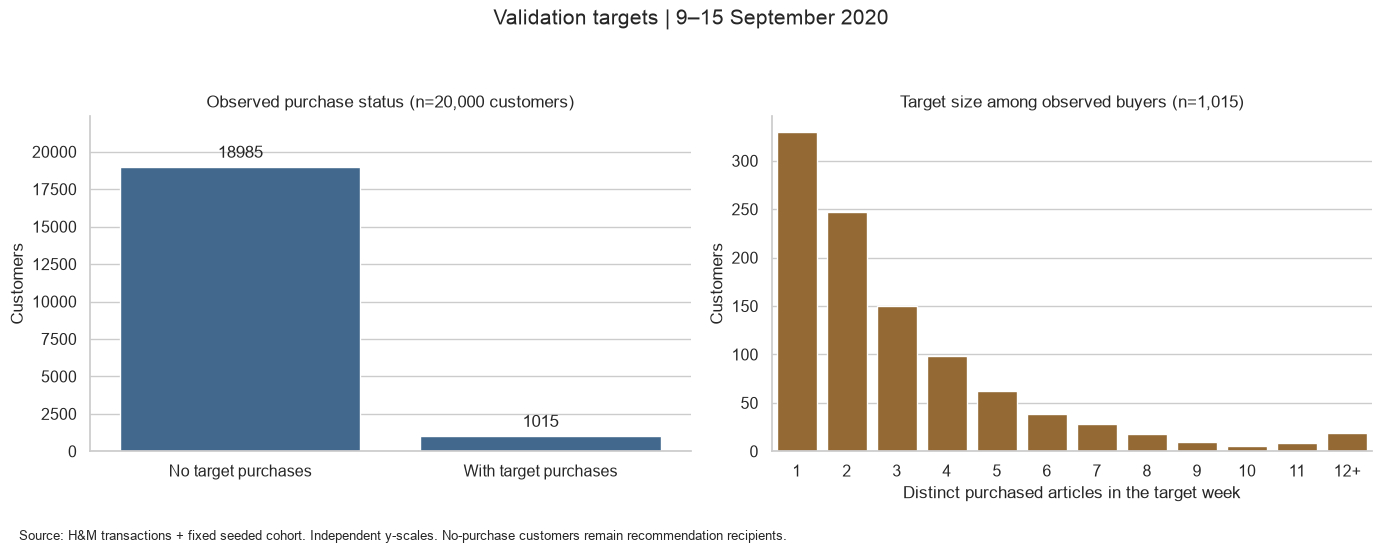

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)

eligibility_counts = pd.Series(
    [n_without_target, n_with_target],
    index=["No target purchases", "With target purchases"],
)
target_size_counts = (
    validation_population.loc[
        validation_population["has_target_purchase"], "n_target_articles"
    ]
    .clip(upper=TOP_K)
    .value_counts()
    .reindex(range(1, TOP_K + 1), fill_value=0)
)
if int(eligibility_counts.sum()) != len(cohort):
    raise ValueError("Eligibility chart counts do not reconcile.")
if int(target_size_counts.sum()) != n_with_target:
    raise ValueError("Target-size chart counts do not reconcile.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.barplot(
    x=eligibility_counts.index, y=eligibility_counts.values,
    color="#356A9A", errorbar=None, ax=axes[0],
)
axes[0].set_title(f"Observed purchase status (n={len(cohort):,} customers)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Customers")
axes[0].bar_label(axes[0].containers[0], fmt="%.0f", padding=4)
axes[0].set_ylim(0, max(eligibility_counts.max() * 1.18, 1))

size_labels = [str(i) for i in range(1, TOP_K)] + [f"{TOP_K}+"]
sns.barplot(
    x=size_labels, y=target_size_counts.values,
    color="#A46B24", errorbar=None, ax=axes[1],
)
axes[1].set_title(f"Target size among observed buyers (n={n_with_target:,})")
axes[1].set_xlabel("Distinct purchased articles in the target week")
axes[1].set_ylabel("Customers")
axes[1].set_ylim(bottom=0)

for ax in axes:
    ax.grid(axis="x", visible=False)
sns.despine(fig=fig)
fig.suptitle("Validation targets | 9–15 September 2020", fontsize=15, y=0.99)
fig.tight_layout(rect=(0, 0.06, 1, 0.94))
fig.text(
    0.02, 0.025,
    "Source: H&M transactions + fixed seeded cohort. Independent y-scales. "
    "No-purchase customers remain recommendation recipients.",
    fontsize=9,
)
plt.show()

### Interpretation

A reference execution of all notebook code cells in a fresh Python process on the documented source files produced:

- 1,015 of 20,000 cohort customers (5.075%) with at least one observed target purchase.
- 18,985 customers (94.925%) without observed target purchases: retain them for recommendations and exclude them only from the declared target-based metrics.
- 3,454 matching source transaction rows, yielding 3,073 distinct customer–article relevance labels. The difference of 381 rows represents repetitions beyond the first occurrence of each pair, not established data errors.
- 330 observed buyers purchased one distinct article and 247 purchased two. Nineteen purchased twelve or more; all their distinct target articles remain in evaluation.

These observations describe the selected cohort and target week only. No observed purchase does not establish dislike or churn. Metric comparisons will involve 1,015 observed buyers rather than the full 20,000-customer recommendation population; use paired comparisons on those same customers and assess uncertainty later.

The saved section 4 outputs agree with these reference observations. The baseline below uses these labels only for scoring.

## 5. Recent-Popularity Baseline

### 5.1. Declare the baseline

**Hypothesis H1:** recent global popularity is a useful reference for retrieving next-week purchases.

- Count source transaction rows per article across **all** customers in the seven days strictly before the validation cutoff: `[2020-09-02, 2020-09-09)`.
- Keep source repetitions in the popularity count. This is transaction-row popularity, not distinct-buyer popularity or revenue.
- Rank by count descending, then lexical article ID ascending for deterministic ties.
- Recommend the same twelve distinct articles to every cohort customer, including customers without target purchases or history.
- Do not remove previously purchased articles: repurchases remain valid outcomes.
- Use only historical transactions to generate recommendations. Target activity and customer eligibility flags are for evaluation only.

Seven days is an initial choice, not a measured optimum. This baseline requires no fitted ML model. A purchase count is a ranking score, not a calibrated probability. Historical purchases do not establish current stock availability.

In [17]:
POPULARITY_DAYS = 7
POPULARITY_START = VALIDATION_CUTOFF - pd.Timedelta(days=POPULARITY_DAYS)

if not 0 < POPULARITY_DAYS <= HISTORY_DAYS:
    raise ValueError("Popularity history must fit the declared feature-history window.")

pd.DataFrame([{
    "method": "recent_popularity_7d",
    "history_start_inclusive": POPULARITY_START,
    "history_end_exclusive": VALIDATION_CUTOFF,
    "ranking_signal": "source transaction rows per article",
    "recommendation_count": TOP_K,
}])

,method,history_start_inclusive,history_end_exclusive,ranking_signal,recommendation_count
0,recent_popularity_7d,2020-09-02,2020-09-09,source transaction rows per article,12


### 5.2. Aggregate global popularity with bounded memory

Count articles within each source chunk, then add those counts across chunks using `Counter`. Do not select a top twelve inside each chunk: an article can accumulate purchases across many chunks.

This helper has no cohort or target-table input, so the population is all historical source customers. Do not assume CSV row order or stop early based on a date.

In [18]:
from collections import Counter


def aggregate_recent_popularity(
    chunks: Iterable[pd.DataFrame],
    *,
    cutoff,
    window_days: int,
) -> pd.DataFrame:
    """Rank articles by global source-row count in [cutoff - window, cutoff)."""
    if window_days <= 0:
        raise ValueError("Popularity window must be positive.")
    cutoff = pd.Timestamp(cutoff)
    start = cutoff - pd.Timedelta(days=window_days)
    if not start < cutoff:
        raise ValueError("Popularity dates must define a valid interval.")

    article_counts = Counter()
    for chunk in chunks:
        dates = pd.to_datetime(chunk["t_dat"], format="%Y-%m-%d", errors="raise")
        recent_articles = chunk.loc[interval_mask(dates, start, cutoff), "article_id"]
        article_counts.update(recent_articles.value_counts().to_dict())

    popularity = (
        pd.Series(article_counts, dtype="int64", name="transaction_rows")
        .rename_axis("article_id")
        .reset_index()
    )
    popularity["article_id"] = popularity["article_id"].astype("string")
    return popularity.sort_values(
        ["transaction_rows", "article_id"], ascending=[False, True]
    ).reset_index(drop=True)

### 5.3. Test the historical window and deterministic ranking

The fixture includes an exact inclusive start, an exact exclusive cutoff, an older purchase and tied counts accumulated across chunks. The expected ranking is `a`, then `b`, with two rows each.

In [19]:
popularity_fixture = [
    pd.DataFrame([
        ["2020-09-09", "future"],
        ["2020-09-02", "b"],
        ["2020-09-01", "old"],
        ["2020-09-08", "a"],
        ["2020-09-08", "b"],
    ], columns=["t_dat", "article_id"], dtype="string"),
    pd.DataFrame([
        ["2020-09-03", "a"],
    ], columns=["t_dat", "article_id"], dtype="string"),
]
fixture_popularity = aggregate_recent_popularity(
    popularity_fixture, cutoff=VALIDATION_CUTOFF, window_days=POPULARITY_DAYS,
)
reordered_popularity = aggregate_recent_popularity(
    [chunk.iloc[::-1] for chunk in reversed(popularity_fixture)],
    cutoff=VALIDATION_CUTOFF, window_days=POPULARITY_DAYS,
)

popularity_fixture_checks = pd.Series({
    "includes_only_eligible_articles": fixture_popularity["article_id"].tolist() == ["a", "b"],
    "counts_across_chunks_and_breaks_ties_by_id": fixture_popularity["transaction_rows"].tolist() == [2, 2],
    "ignores_row_and_chunk_order": fixture_popularity.equals(reordered_popularity),
    "handles_empty_history": aggregate_recent_popularity(
        [], cutoff=VALIDATION_CUTOFF, window_days=POPULARITY_DAYS
    ).empty,
}, name="passed")

if not popularity_fixture_checks.all():
    raise ValueError("Popularity fixture checks failed.")
popularity_fixture_checks.to_frame()

,passed
includes_only_eligible_articles,True
counts_across_chunks_and_breaks_ties_by_id,True
ignores_row_and_chunk_order,True
handles_empty_history,True


### 5.4. Compute the real historical ranking

Scan only date and article columns. No future outcome is retained or used by this aggregation. The CSV scan is required by its storage layout, not by the model's information requirements.

In [20]:
with read_source_chunks(
    RAW_DATA_DIRECTORY / "transactions_train.csv",
    columns=["t_dat", "article_id"],
    chunk_rows=TARGET_CHUNK_ROWS,
) as chunks:
    validation_popularity = aggregate_recent_popularity(
        report_scan_progress(chunks),
        cutoff=VALIDATION_CUTOFF,
        window_days=POPULARITY_DAYS,
    )

if len(validation_popularity) < TOP_K:
    raise ValueError("Not enough historical articles to issue twelve distinct recommendations.")
if not validation_popularity["article_id"].is_unique:
    raise ValueError("Popularity ranking contains repeated article IDs.")

baseline_top_articles = validation_popularity.head(TOP_K).copy()
baseline_top_articles.insert(0, "rank", range(1, TOP_K + 1))

print(f"Historical transaction rows: {int(validation_popularity['transaction_rows'].sum()):,}")
print(f"Distinct articles observed in this historical window: {len(validation_popularity):,}")
baseline_top_articles

Reading source chunk 10...
Reading source chunk 20...
Reading source chunk 30...
Reading source chunk 40...
Reading source chunk 50...
Reading source chunk 60...
Historical transaction rows: 264,657
Distinct articles observed in this historical window: 19,362


,rank,article_id,transaction_rows
0,1,0915526001,779
1,2,0751471043,757
2,3,0751471001,724
3,4,0706016001,683
4,5,0919365008,614
5,6,0915529003,606
6,7,0918292001,584
7,8,0863595006,536
8,9,0896152002,535
9,10,0448509014,529


### 5.5. Issue twelve distinct recommendations to every cohort customer

The small cross join creates 20,000 × 12 recommendation rows, rather than a customer × full-catalogue matrix. The count column is retained for traceability and has no probability interpretation.

The target-purchase population is not involved in this step.

In [21]:
baseline_recommendations = cohort.merge(baseline_top_articles, how="cross")

recommendation_counts = baseline_recommendations.groupby("customer_id").size()
recommendation_checks = pd.Series({
    "all_cohort_customers_receive_recommendations": (
        len(recommendation_counts) == len(cohort)
        and set(recommendation_counts.index) == set(cohort_ids)
    ),
    "exactly_twelve_recommendations_per_customer": recommendation_counts.eq(TOP_K).all(),
    "no_repeated_customer_article_pairs": not baseline_recommendations.duplicated(["customer_id", "article_id"]).any(),
    "all_ranks_are_valid": baseline_recommendations["rank"].between(1, TOP_K).all(),
    "top_articles_come_from_historical_ranking": baseline_top_articles["article_id"].isin(validation_popularity["article_id"]).all(),
}, name="passed")

if not recommendation_checks.all():
    raise ValueError("Baseline recommendation checks failed.")
recommendation_checks.to_frame()

,passed
all_cohort_customers_receive_recommendations,True
exactly_twelve_recommendations_per_customer,True
no_repeated_customer_article_pairs,True
all_ranks_are_valid,True
top_articles_come_from_historical_ranking,True


### 5.6. Implement the declared ranking metrics

For a customer with a nonempty distinct target set `R`:

- **Recall@k** = number of target articles retrieved in the first `k` recommendations / `len(R)`.
- **AP@k** = sum of precision at each relevant position / `min(k, len(R))`.
- **MAP@k** = mean AP@k over eligible customers, with equal customer weights.

Use all target articles in the denominators, including those absent from recommendations or future candidates. Reject duplicate top-k predictions and empty target sets; exclude customers without targets explicitly before averaging rather than assigning them an invented zero score.

For `R={a,b}` and predictions `[x,a,b]`, precision at the two relevant positions is `1/2` and `2/3`, so AP@3 = `(1/2 + 2/3) / 2 = 7/12`. Recall@3 = 1. Moving relevant articles earlier improves AP while leaving recall unchanged.

In [22]:
def score_recommendation_list(
    relevant_articles,
    recommended_articles,
    *,
    k: int,
) -> dict:
    """Score a distinct top-k ranking against a nonempty, unfiltered target set."""
    if k <= 0:
        raise ValueError("k must be positive.")
    relevant = set(relevant_articles)
    if not relevant:
        raise ValueError("Target-based metrics require at least one relevant article.")
    predictions = list(recommended_articles)[:k]
    if len(predictions) != k or len(set(predictions)) != k:
        raise ValueError("Predictions must contain at least k distinct top-k articles.")

    n_hits = 0
    precision_sum = 0.0
    for rank, article_id in enumerate(predictions, start=1):
        if article_id in relevant:
            n_hits += 1
            precision_sum += n_hits / rank

    return {
        "n_target_articles": len(relevant),
        "n_hits": n_hits,
        "ap_at_k": precision_sum / min(k, len(relevant)),
        "recall_at_k": n_hits / len(relevant),
    }

### 5.7. Test metrics against hand-calculated examples

Cover ordering, no matches, target sets larger than k, targets absent from recommendations, and explicit rejection of duplicate predictions or empty targets. These tests establish metric conventions before any real performance interpretation.

In [23]:
from math import isclose

late_hits = score_recommendation_list({"a", "b"}, ["x", "a", "b"], k=3)
early_hits = score_recommendation_list({"a", "b"}, ["a", "b", "x"], k=3)
large_target = score_recommendation_list({"a", "b", "c", "d"}, ["a", "b"], k=2)
missing_target = score_recommendation_list({"a", "unretrieved"}, ["a", "x"], k=2)
no_hits = score_recommendation_list({"a"}, ["x", "y"], k=2)

invalid_metric_cases = [
    ({"a"}, ["a", "a"], 2),
    (set(), ["a", "b"], 2),
    ({"a"}, ["a"], 2),
    ({"a"}, ["a"], 0),
]
invalid_cases_rejected = []
for relevant, predictions, k in invalid_metric_cases:
    try:
        score_recommendation_list(relevant, predictions, k=k)
    except ValueError:
        invalid_cases_rejected.append(True)
    else:
        invalid_cases_rejected.append(False)

metric_checks = pd.Series({
    "manual_ap_matches_seven_twelfths": isclose(late_hits["ap_at_k"], 7 / 12),
    "earlier_hits_improve_ap_at_same_recall": (
        early_hits["ap_at_k"] > late_hits["ap_at_k"]
        and early_hits["recall_at_k"] == late_hits["recall_at_k"] == 1
    ),
    "ap_and_recall_use_their_declared_denominators": large_target["ap_at_k"] == 1 and large_target["recall_at_k"] == 0.5,
    "unretrieved_targets_stay_in_denominator": missing_target["ap_at_k"] == missing_target["recall_at_k"] == 0.5,
    "no_hits_produce_zero_scores": no_hits["ap_at_k"] == no_hits["recall_at_k"] == 0,
    "invalid_metric_inputs_are_rejected": all(invalid_cases_rejected),
}, name="passed")

if not metric_checks.all():
    raise ValueError("Ranking metric checks failed.")
metric_checks.to_frame()

,passed
manual_ap_matches_seven_twelfths,True
earlier_hits_improve_ap_at_same_recall,True
ap_and_recall_use_their_declared_denominators,True
unretrieved_targets_stay_in_denominator,True
no_hits_produce_zero_scores,True
invalid_metric_inputs_are_rejected,True


### 5.8. Score validation buyers and retain per-customer results

All recommendation lists are identical for this global baseline, so score the common list once per observed buyer. Preserve per-customer scores for later paired comparisons and history-segment diagnostics.

The primary recall below is **macro recall**: average each customer's recall with equal weight. Pooled hits divided by pooled target pairs is a separate **micro recall** diagnostic. Do not substitute one for the other.

In [24]:
validation_relevant_articles = (
    validation_targets.groupby("customer_id")["article_id"].agg(set).to_dict()
)
baseline_article_ids = baseline_top_articles["article_id"].tolist()

baseline_customer_scores = pd.DataFrame([
    {
        "customer_id": customer_id,
        **score_recommendation_list(relevant, baseline_article_ids, k=TOP_K),
    }
    for customer_id, relevant in validation_relevant_articles.items()
])

if len(baseline_customer_scores) != n_with_target:
    raise ValueError("Metric population differs from the declared observed buyers.")
if not baseline_customer_scores[["ap_at_k", "recall_at_k"]].ge(0).all().all():
    raise ValueError("Ranking scores must be nonnegative.")
if not baseline_customer_scores[["ap_at_k", "recall_at_k"]].le(1).all().all():
    raise ValueError("Ranking scores must not exceed one.")

baseline_results = pd.DataFrame([{
    "method": "recent_popularity_7d",
    "map_at_12": baseline_customer_scores["ap_at_k"].mean(),
    "recall_at_12": baseline_customer_scores["recall_at_k"].mean(),
    "micro_recall_at_12": baseline_customer_scores["n_hits"].sum() / len(validation_targets),
    "customers_with_any_hit": int(baseline_customer_scores["n_hits"].gt(0).sum()),
    "retrieved_target_pairs": int(baseline_customer_scores["n_hits"].sum()),
    "evaluated_customers": len(baseline_customer_scores),
    "recommendation_customers": len(cohort),
    "excluded_from_metrics_share_pct": 100 * n_without_target / len(cohort),
    "distinct_recommended_articles": baseline_top_articles["article_id"].nunique(),
}])

baseline_results.T.rename(columns={0: "value"})

,value
method,recent_popularity_7d
map_at_12,0.005443
recall_at_12,0.019836
micro_recall_at_12,0.018549
customers_with_any_hit,54
retrieved_target_pairs,57
evaluated_customers,1015
recommendation_customers,20000
excluded_from_metrics_share_pct,94.925
distinct_recommended_articles,12


### 5.9. Inspect rank-level matches and cumulative recall

For this common ranking, count how many eligible customers purchased the article at each rank. Cumulative recall remains an equal-weight customer average. Its value at k=12 must match the reported Recall@12.

This diagnostic uses validation outcomes to describe the issued ranking. Do not reorder predictions using these matches and still present the result as the original popularity baseline.

In [25]:
rank_diagnostics = baseline_top_articles[["rank", "article_id", "transaction_rows"]].copy()
rank_diagnostics["validation_buyers_with_article"] = [
    sum(article_id in relevant for relevant in validation_relevant_articles.values())
    for article_id in baseline_article_ids
]
rank_diagnostics["cumulative_macro_recall"] = [
    sum(
        len(relevant.intersection(baseline_article_ids[:k])) / len(relevant)
        for relevant in validation_relevant_articles.values()
    ) / len(validation_relevant_articles)
    for k in range(1, TOP_K + 1)
]

if int(rank_diagnostics["validation_buyers_with_article"].sum()) != int(baseline_customer_scores["n_hits"].sum()):
    raise ValueError("Rank-level hits do not reconcile with customer-level hits.")
if not isclose(rank_diagnostics["cumulative_macro_recall"].iloc[-1], baseline_results["recall_at_12"].iloc[0]):
    raise ValueError("Recall diagnostics do not match the primary result.")

rank_diagnostics

,rank,article_id,transaction_rows,validation_buyers_with_article,cumulative_macro_recall
0,1,0915526001,779,4,0.001658
1,2,0751471043,757,6,0.004105
2,3,0751471001,724,3,0.004821
3,4,0706016001,683,8,0.006546
4,5,0919365008,614,3,0.007613
5,6,0915529003,606,4,0.008936
6,7,0918292001,584,13,0.014626
7,8,0863595006,536,4,0.016068
8,9,0896152002,535,5,0.018236
9,10,0448509014,529,4,0.018818


### 5.10. Visualise historical popularity and validation retrieval

Left: source transaction counts for the twelve recommended articles, ordered by historical rank (2–8 September). Right: cumulative macro recall on observed validation buyers (9–15 September), as more positions are considered. Units and time windows differ and are labelled separately. This is one baseline, not evidence that personalisation improves performance.

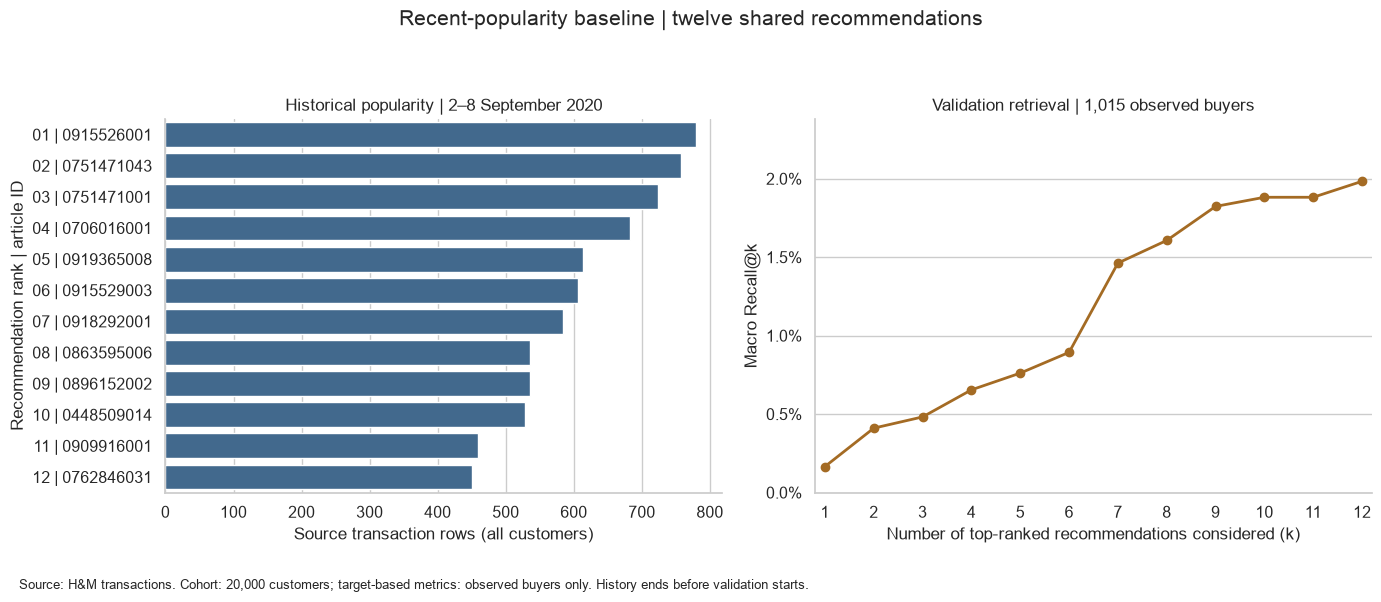

In [26]:
from matplotlib.ticker import PercentFormatter

fig_baseline, axes = plt.subplots(1, 2, figsize=(14, 6))
rank_labels = [
    f"{rank:02d} | {article_id}"
    for rank, article_id in zip(baseline_top_articles["rank"], baseline_article_ids)
]
sns.barplot(
    x=baseline_top_articles["transaction_rows"], y=rank_labels,
    color="#356A9A", errorbar=None, ax=axes[0],
)
axes[0].set_title("Historical popularity | 2–8 September 2020")
axes[0].set_xlabel("Source transaction rows (all customers)")
axes[0].set_ylabel("Recommendation rank | article ID")
axes[0].grid(axis="y", visible=False)
axes[0].set_xlim(left=0)

axes[1].plot(
    rank_diagnostics["rank"], rank_diagnostics["cumulative_macro_recall"],
    marker="o", color="#A46B24", linewidth=2,
)
axes[1].set_title(f"Validation retrieval | {n_with_target:,} observed buyers")
axes[1].set_xlabel("Number of top-ranked recommendations considered (k)")
axes[1].set_ylabel("Macro Recall@k")
axes[1].set_xticks(range(1, TOP_K + 1))
axes[1].set_xlim(0.8, TOP_K + 0.2)
axes[1].set_ylim(0, max(0.01, rank_diagnostics["cumulative_macro_recall"].max() * 1.2))
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
axes[1].grid(axis="x", visible=False)
sns.despine(fig=fig_baseline)
fig_baseline.suptitle("Recent-popularity baseline | twelve shared recommendations", fontsize=15, y=0.99)
fig_baseline.tight_layout(rect=(0, 0.07, 1, 0.94))
fig_baseline.text(
    0.02, 0.025,
    "Source: H&M transactions. Cohort: 20,000 customers; target-based metrics: observed buyers only. "
    "History ends before validation starts.",
    fontsize=9,
)
plt.show()

### Interpretation

A reference execution of all 26 code cells in a fresh Python process on the documented source files produced:

- 264,657 historical transaction rows across 19,362 articles in 2–8 September 2020.
- Twelve distinct recommendations for each of 20,000 cohort customers (240,000 recommendation rows).
- Validation MAP@12 = 0.005442630 on 1,015 observed buyers.
- Validation macro Recall@12 = 0.019836223 (1.9836%).
- Fifty-seven retrieved customer–article target pairs, with at least one hit for 54 observed buyers.
- Micro Recall@12 = 57 / 3,073 = 0.018548650 (1.8549%). This pooled fraction differs from the equal-weight customer average above.

An independent relational join of recommendation rows and target pairs reproduces every per-customer AP, recall and total hit count. Metric tests and recommendation checks pass.

This establishes a reference point; no comparison with a learned or personalised method has been performed. MAP@12 is a ranking score and macro Recall@12 is an average fraction of retrieved target articles, not overall accuracy, conversion or revenue impact. The one-week, 1,015-buyer evaluation has limited temporal scope; uncertainty and broader historical robustness remain to assess.

All 20,000 cohort customers receive recommendations. Twelve distinct articles across the whole cohort demonstrate the limited catalogue diversity of this global baseline. No eligible-catalogue coverage ratio or candidate-generation coverage has been defined at this milestone.

The saved section 5 outputs agree with the reference observations above. The next section adds the first personalised baseline. Local-test outcomes remain unevaluated.

## 6. Recent Purchases with Popularity Fallback

### 6.1. Declare the personalised rule

**Hypothesis H3:** previously purchased articles may be useful recommendations when ranked by their most recent observed purchase.

1. Use cohort transactions in `[cutoff - 180 days, cutoff)`.
2. Aggregate one row per customer–article pair: last purchase date and retained source-row count.
3. Order each customer's articles by last purchase date descending, then article ID ascending. Same-day purchase order is unknown; the ID is only a deterministic tie-breaker.
4. Retain up to twelve distinct historical articles, then fill vacant positions with the existing seven-day global popularity ranking, skipping duplicates.
5. Issue twelve distinct recommendations to every cohort customer. A customer without history receives the same global top twelve as before.

The initial 180-day window is not an observed optimum. Frequency is recorded for later feature work but is not a ranking criterion in this baseline. Historical purchases do not establish stock availability, and missing history does not establish a newly created account.

This evaluates the stated recency heuristic, not the best achievable repurchase strategy. Metadata, target purchases and future eligibility flags are not recommendation inputs.

In [27]:
PERSONAL_HISTORY_START = VALIDATION_CUTOFF - pd.Timedelta(days=HISTORY_DAYS)
PERSONAL_METHOD = f"recent_purchases_{HISTORY_DAYS}d_popularity_{POPULARITY_DAYS}d"

pd.DataFrame([{
    "method": PERSONAL_METHOD,
    "personal_history_start_inclusive": PERSONAL_HISTORY_START,
    "personal_history_end_exclusive": VALIDATION_CUTOFF,
    "fallback_method": "recent_popularity_7d",
    "recommendation_count": TOP_K,
}])

,method,personal_history_start_inclusive,personal_history_end_exclusive,fallback_method,recommendation_count
0,recent_purchases_180d_popularity_7d,2020-03-13,2020-09-09,recent_popularity_7d,12


### 6.2. Aggregate cutoff-safe customer–article history

Filter each chunk by fixed cohort membership and the historical interval. Aggregate last purchase date and source-row count within chunks, then reconcile the same customer–article pair across all chunks using `max` and `sum`.

`days_since_last_purchase` is the calendar-day difference from the cutoff. A purchase on 8 September has a recency of one day on 9 September. These are historical features; validation labels remain in their separate tables.

In [28]:
def build_customer_article_history(
    chunks: Iterable[pd.DataFrame],
    customer_ids: pd.Index,
    *,
    cutoff,
    window_days: int,
) -> pd.DataFrame:
    """Aggregate per-customer article recency and row counts strictly before cutoff."""
    if window_days <= 0:
        raise ValueError("History window must be positive.")
    cutoff = pd.Timestamp(cutoff)
    start = cutoff - pd.Timedelta(days=window_days)
    if not start < cutoff:
        raise ValueError("History dates must define a valid interval.")

    parts = []
    for chunk in chunks:
        selected = chunk.loc[
            chunk["customer_id"].isin(customer_ids),
            ["t_dat", "customer_id", "article_id"],
        ].copy()
        if selected.empty:
            continue
        selected["t_dat"] = pd.to_datetime(
            selected["t_dat"], format="%Y-%m-%d", errors="raise"
        )
        selected = selected.loc[interval_mask(selected["t_dat"], start, cutoff)]
        if not selected.empty:
            parts.append(selected.groupby(["customer_id", "article_id"], as_index=False).agg(
                last_purchase_date=("t_dat", "max"),
                history_transaction_rows=("t_dat", "size"),
            ))

    if not parts:
        return pd.DataFrame({
            "customer_id": pd.Series(dtype="string"),
            "article_id": pd.Series(dtype="string"),
            "last_purchase_date": pd.Series(dtype="datetime64[ns]"),
            "history_transaction_rows": pd.Series(dtype="int64"),
            "days_since_last_purchase": pd.Series(dtype="int64"),
        })

    history = pd.concat(parts, ignore_index=True).groupby(
        ["customer_id", "article_id"], as_index=False
    ).agg(
        last_purchase_date=("last_purchase_date", "max"),
        history_transaction_rows=("history_transaction_rows", "sum"),
    )
    history["days_since_last_purchase"] = (cutoff - history["last_purchase_date"]).dt.days
    return history.sort_values(
        ["customer_id", "last_purchase_date", "article_id"],
        ascending=[True, False, True],
    ).reset_index(drop=True)

### 6.3. Generate distinct recommendations and record their source

The generator uses only cohort IDs, historical customer–article rows and the historical popularity order. It never receives target purchases or `has_target_purchase`.

Use the `source` column to distinguish personalised history recommendations from popularity fallback. Stop when k articles have been selected; do not build a customer × full-catalogue matrix.

In [29]:
def recommend_recent_purchases(
    customer_ids: pd.Index,
    customer_article_history: pd.DataFrame,
    popular_article_ids,
    *,
    k: int,
) -> pd.DataFrame:
    """Prioritise latest purchased articles, then fill from distinct popularity order."""
    if k <= 0:
        raise ValueError("k must be positive.")
    if not customer_ids.is_unique:
        raise ValueError("Recommendation customer IDs must be unique.")
    if customer_article_history.duplicated(["customer_id", "article_id"]).any():
        raise ValueError("Historical customer–article pairs must be unique.")
    popularity_order = list(dict.fromkeys(popular_article_ids))
    if len(popularity_order) < k:
        raise ValueError("Fallback must contain at least k distinct articles.")

    ordered_history = customer_article_history.sort_values(
        ["customer_id", "last_purchase_date", "article_id"],
        ascending=[True, False, True],
    )
    recent_by_customer = (
        ordered_history.groupby("customer_id")["article_id"].agg(list).to_dict()
    )

    rows = []
    for customer_id in customer_ids:
        chosen = recent_by_customer.get(customer_id, [])[:k]
        seen = set(chosen)
        sources = ["recent_purchase"] * len(chosen)
        if len(chosen) < k:
            for article_id in popularity_order:
                if article_id not in seen:
                    chosen.append(article_id)
                    sources.append("popularity_fallback")
                    seen.add(article_id)
                if len(chosen) == k:
                    break
        rows.extend(
            (customer_id, article_id, rank, source)
            for rank, (article_id, source) in enumerate(zip(chosen, sources), start=1)
        )

    return pd.DataFrame(rows, columns=["customer_id", "article_id", "rank", "source"])

### 6.4. Test historical boundaries, recency, ties and fallback

The fixture repeats article x across chunks and includes a cutoff-day purchase, an older-than-window purchase, an exact history-start purchase and an outside-cohort customer. Customers a and b have history, while c has none.

At k=3 with popularity `[x,z,y,q]`, expected recommendations are a: `[x,y,z]`, b: `[edge,x,z]`, c: `[x,z,y]`. Same-day ties use article ID, repeated historical articles occur once, and fallback skips already selected articles.

In [30]:
personal_fixture_chunks = [
    pd.DataFrame([
        ["2020-03-12", "a", "old"],
        ["2020-03-13", "b", "edge"],
        ["2020-09-08", "a", "x"],
        ["2020-09-09", "a", "future"],
        ["2020-09-04", "outside", "z"],
    ], columns=["t_dat", "customer_id", "article_id"], dtype="string"),
    pd.DataFrame([
        ["2020-09-01", "a", "x"],
        ["2020-09-08", "a", "y"],
    ], columns=["t_dat", "customer_id", "article_id"], dtype="string"),
]
personal_fixture_ids = pd.Index(["a", "b", "c"], dtype="string")
personal_fixture_history = build_customer_article_history(
    personal_fixture_chunks, personal_fixture_ids,
    cutoff=VALIDATION_CUTOFF, window_days=HISTORY_DAYS,
)
personal_fixture_reordered = build_customer_article_history(
    [chunk.iloc[::-1] for chunk in reversed(personal_fixture_chunks)], personal_fixture_ids,
    cutoff=VALIDATION_CUTOFF, window_days=HISTORY_DAYS,
)
personal_fixture_recommendations = recommend_recent_purchases(
    personal_fixture_ids, personal_fixture_history, ["x", "z", "y", "q"], k=3,
)
personal_fixture_lists = personal_fixture_recommendations.groupby("customer_id")["article_id"].agg(list).to_dict()
x_history = personal_fixture_history.loc[personal_fixture_history["article_id"].eq("x")].iloc[0]

personal_fixture_checks = pd.Series({
    "retains_only_historical_cohort_pairs": set(map(tuple, personal_fixture_history[["customer_id", "article_id"]].to_numpy())) == {("a", "x"), ("a", "y"), ("b", "edge")},
    "combines_repeated_pair_across_chunks": x_history["history_transaction_rows"] == 2 and x_history["days_since_last_purchase"] == 1,
    "includes_exact_180_day_start": personal_fixture_history.loc[personal_fixture_history["article_id"].eq("edge"), "days_since_last_purchase"].iloc[0] == HISTORY_DAYS,
    "ignores_row_and_chunk_order": personal_fixture_history.equals(personal_fixture_reordered),
    "resolves_ties_and_skips_fallback_duplicates": personal_fixture_lists["a"] == ["x", "y", "z"],
    "fills_partial_history": personal_fixture_lists["b"] == ["edge", "x", "z"],
    "no_history_receives_global_top_k": personal_fixture_lists["c"] == ["x", "z", "y"],
    "records_all_fallback_for_no_history": personal_fixture_recommendations.loc[personal_fixture_recommendations["customer_id"].eq("c"), "source"].eq("popularity_fallback").all(),
    "handles_empty_historical_input": build_customer_article_history([], personal_fixture_ids, cutoff=VALIDATION_CUTOFF, window_days=HISTORY_DAYS).empty,
}, name="passed")

if not personal_fixture_checks.all():
    failed = personal_fixture_checks.index[~personal_fixture_checks].tolist()
    raise ValueError(f"Personalised fixture checks failed: {failed}")
personal_fixture_checks.to_frame()

,passed
retains_only_historical_cohort_pairs,True
combines_repeated_pair_across_chunks,True
includes_exact_180_day_start,True
ignores_row_and_chunk_order,True
resolves_ties_and_skips_fallback_duplicates,True
fills_partial_history,True
no_history_receives_global_top_k,True
records_all_fallback_for_no_history,True
handles_empty_historical_input,True


### 6.5. Build the real cohort history and preserve customers without history

Only fixed-cohort transactions from the historical window enter the aggregate. Summarise distinct historical articles per customer, preserving the complete cohort with a left join. A zero count means no observed purchases in this window; it does not establish registration date or absence of older activity.

In [31]:
with read_source_chunks(
    RAW_DATA_DIRECTORY / "transactions_train.csv",
    columns=["t_dat", "customer_id", "article_id"],
    chunk_rows=TARGET_CHUNK_ROWS,
) as chunks:
    customer_article_history = build_customer_article_history(
        report_scan_progress(chunks), cohort_ids,
        cutoff=VALIDATION_CUTOFF, window_days=HISTORY_DAYS,
    )

if customer_article_history.duplicated(["customer_id", "article_id"]).any():
    raise ValueError("Real historical customer–article pairs must be unique.")
if not customer_article_history["days_since_last_purchase"].between(1, HISTORY_DAYS).all():
    raise ValueError("Historical recency lies outside the declared interval.")
if not customer_article_history["customer_id"].isin(cohort_ids).all():
    raise ValueError("History contains a customer outside the fixed cohort.")

observed_customer_history = customer_article_history.groupby("customer_id", as_index=False).agg(
    n_history_articles=("article_id", "size"),
    history_transaction_rows=("history_transaction_rows", "sum"),
)
customer_history_summary = cohort.merge(
    observed_customer_history, on="customer_id", how="left", validate="one_to_one",
)
for column in ["n_history_articles", "history_transaction_rows"]:
    customer_history_summary[column] = customer_history_summary[column].fillna(0).astype("int64")
customer_history_summary["has_history"] = customer_history_summary["n_history_articles"].gt(0)

pd.Series({
    "cohort_customers": len(customer_history_summary),
    "customers_with_180d_history": int(customer_history_summary["has_history"].sum()),
    "customers_without_180d_history": int((~customer_history_summary["has_history"]).sum()),
    "historical_source_rows": int(customer_article_history["history_transaction_rows"].sum()),
    "distinct_customer_article_history_pairs": len(customer_article_history),
}, name="value").to_frame()

Reading source chunk 10...
Reading source chunk 20...
Reading source chunk 30...
Reading source chunk 40...
Reading source chunk 50...
Reading source chunk 60...


,value
cohort_customers,20000
customers_with_180d_history,10667
customers_without_180d_history,9333
historical_source_rows,113678
distinct_customer_article_history_pairs,98782


### 6.6. Recommend twelve distinct articles and verify their provenance

For each customer, the personalised row count must equal the smaller of twelve and the number of historical articles. Customers without history must receive exactly the original popularity list. The source column records provenance, not a calibrated score.

In [32]:
personal_recommendations = recommend_recent_purchases(
    cohort_ids, customer_article_history,
    validation_popularity["article_id"].tolist(), k=TOP_K,
)
personal_recommendation_lists = (
    personal_recommendations.sort_values(["customer_id", "rank"])
    .groupby("customer_id")["article_id"].agg(list).to_dict()
)
personal_counts = personal_recommendations.groupby("customer_id").size()
recent_source_counts = (
    personal_recommendations.loc[personal_recommendations["source"].eq("recent_purchase")]
    .groupby("customer_id").size()
)
expected_recent_counts = customer_history_summary.set_index("customer_id")["n_history_articles"].clip(upper=TOP_K)
actual_recent_counts = recent_source_counts.reindex(expected_recent_counts.index, fill_value=0)
no_history_ids = customer_history_summary.loc[~customer_history_summary["has_history"], "customer_id"]

personal_recommendation_checks = pd.Series({
    "covers_every_cohort_customer": set(personal_recommendation_lists) == set(cohort_ids),
    "twelve_recommendations_per_customer": personal_counts.eq(TOP_K).all(),
    "no_duplicate_customer_article_pairs": not personal_recommendations.duplicated(["customer_id", "article_id"]).any(),
    "personalised_count_matches_available_history": actual_recent_counts.eq(expected_recent_counts).all(),
    "no_history_lists_match_global_baseline": all(personal_recommendation_lists[customer_id] == baseline_article_ids for customer_id in no_history_ids),
}, name="passed")

if not personal_recommendation_checks.all():
    raise ValueError("Personalised recommendation checks failed.")
personal_recommendation_checks.to_frame()

,passed
covers_every_cohort_customer,True
twelve_recommendations_per_customer,True
no_duplicate_customer_article_pairs,True
personalised_count_matches_available_history,True
no_history_lists_match_global_baseline,True


### 6.7. Compare using the identical target sets and metric function

The evaluation loop uses every observed validation buyer and their complete distinct target set. Reuse the existing metric helper without changing denominators or eligibility.

`distinct_recommended_articles` is a count across the entire 20,000-customer recommendation population, not a ratio against an eligible catalogue. The frequency and recency aggregates are not fitted model weights.

In [33]:
personal_customer_scores = pd.DataFrame([
    {
        "customer_id": customer_id,
        **score_recommendation_list(
            relevant, personal_recommendation_lists[customer_id], k=TOP_K
        ),
    }
    for customer_id, relevant in validation_relevant_articles.items()
])
if set(personal_customer_scores["customer_id"]) != set(baseline_customer_scores["customer_id"]):
    raise ValueError("Methods must use the same metric-eligible customers.")
if not personal_customer_scores[["ap_at_k", "recall_at_k"]].ge(0).all().all() or not personal_customer_scores[["ap_at_k", "recall_at_k"]].le(1).all().all():
    raise ValueError("Personalised ranking metrics must lie between zero and one.")

personal_results = pd.DataFrame([{
    "method": PERSONAL_METHOD,
    "map_at_12": personal_customer_scores["ap_at_k"].mean(),
    "recall_at_12": personal_customer_scores["recall_at_k"].mean(),
    "micro_recall_at_12": personal_customer_scores["n_hits"].sum() / len(validation_targets),
    "customers_with_any_hit": int(personal_customer_scores["n_hits"].gt(0).sum()),
    "retrieved_target_pairs": int(personal_customer_scores["n_hits"].sum()),
    "evaluated_customers": len(personal_customer_scores),
    "recommendation_customers": len(cohort),
    "excluded_from_metrics_share_pct": 100 * n_without_target / len(cohort),
    "distinct_recommended_articles": personal_recommendations["article_id"].nunique(),
}])
baseline_comparison = pd.concat([baseline_results, personal_results], ignore_index=True)
baseline_comparison.set_index("method").T

method,recent_popularity_7d,recent_purchases_180d_popularity_7d
map_at_12,0.005443,0.022168
recall_at_12,0.019836,0.044635
micro_recall_at_12,0.018549,0.036121
customers_with_any_hit,54.000000,89.000000
retrieved_target_pairs,57.000000,111.000000
evaluated_customers,1015.000000,1015.000000
recommendation_customers,20000.000000,20000.000000
excluded_from_metrics_share_pct,94.925000,94.925000
distinct_recommended_articles,12.000000,16857.000000


### 6.8. Inspect paired differences and history segments

Both methods are scored on exactly the same customers. Compute each customer's score difference before summarising gains, ties and losses. Also compare customers with and without 180-day history using historical membership only (H4).

MAP and Recall remain equal-weight customer averages within each segment. Show the segment size. These are descriptive validation comparisons; no statistical significance or temporal robustness is established.

In [34]:
paired_scores = baseline_customer_scores.merge(
    personal_customer_scores, on="customer_id", how="inner",
    suffixes=("_popularity", "_personal"), validate="one_to_one",
).merge(
    customer_history_summary[["customer_id", "has_history"]],
    on="customer_id", how="left", validate="one_to_one",
)
if len(paired_scores) != n_with_target or paired_scores["has_history"].isna().any():
    raise ValueError("Paired comparison must preserve all eligible customers and history flags.")
if not paired_scores["n_target_articles_popularity"].eq(paired_scores["n_target_articles_personal"]).all():
    raise ValueError("Methods must retain identical target-set sizes.")
paired_scores["delta_ap"] = paired_scores["ap_at_k_personal"] - paired_scores["ap_at_k_popularity"]
paired_scores["delta_recall"] = paired_scores["recall_at_k_personal"] - paired_scores["recall_at_k_popularity"]

if not paired_scores.loc[~paired_scores["has_history"], ["delta_ap", "delta_recall"]].eq(0).all().all():
    raise ValueError("Without history, both methods must produce identical scores.")

paired_summary = pd.Series({
    "eligible_customers": len(paired_scores),
    "customers_with_higher_ap": int(paired_scores["delta_ap"].gt(1e-12).sum()),
    "customers_with_equal_ap": int(paired_scores["delta_ap"].abs().le(1e-12).sum()),
    "customers_with_lower_ap": int(paired_scores["delta_ap"].lt(-1e-12).sum()),
    "mean_ap_difference": paired_scores["delta_ap"].mean(),
    "mean_recall_difference": paired_scores["delta_recall"].mean(),
}, name="value").to_frame()
print(paired_summary.to_string())

history_segment_results = paired_scores.groupby("has_history").agg(
    evaluated_customers=("customer_id", "size"),
    popularity_map_at_12=("ap_at_k_popularity", "mean"),
    personal_map_at_12=("ap_at_k_personal", "mean"),
    popularity_recall_at_12=("recall_at_k_popularity", "mean"),
    personal_recall_at_12=("recall_at_k_personal", "mean"),
)
history_segment_results.index = history_segment_results.index.map({False: "No 180-day history", True: "Has 180-day history"})
history_segment_results

                                value
eligible_customers        1015.000000
customers_with_higher_ap    64.000000
customers_with_equal_ap    905.000000
customers_with_lower_ap     46.000000
mean_ap_difference           0.016726
mean_recall_difference       0.024799


,evaluated_customers,popularity_map_at_12,personal_map_at_12,popularity_recall_at_12,personal_recall_at_12
has_history,,,,,
No 180-day history,187,0.002338,0.002338,0.013146,0.013146
Has 180-day history,828,0.006144,0.026647,0.021347,0.051747


### 6.9. Visualise the comparison

The same 1,015 observed validation buyers contribute equally to each method. Bars start at zero. AP is shown as a ranking score; recall uses percentage labels. The panels have separate vertical scales because their metrics differ. These are point estimates from one target week.

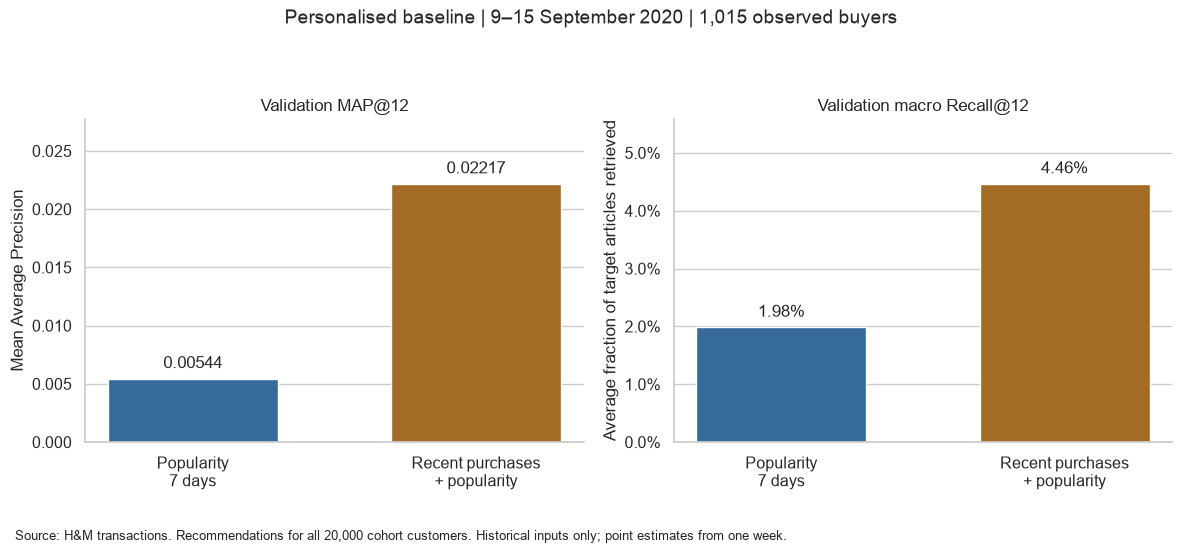

In [35]:
comparison_labels = ['Popularity\n7 days', 'Recent purchases\n+ popularity']
comparison_colours = ["#356A9A", "#A46B24"]
fig_personal, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for ax, metric, title in zip(
    axes, ["map_at_12", "recall_at_12"], ["Validation MAP@12", "Validation macro Recall@12"],
):
    values = baseline_comparison[metric].tolist()
    ax.bar(comparison_labels, values, color=comparison_colours, width=0.6)
    ax.set_title(title)
    ax.set_ylim(0, max(max(values) * 1.25, 0.001))
    ax.grid(axis="x", visible=False)
    if metric == "recall_at_12":
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
        labels = [f"{value:.2%}" for value in values]
        ax.set_ylabel("Average fraction of target articles retrieved")
    else:
        labels = [f"{value:.5f}" for value in values]
        ax.set_ylabel("Mean Average Precision")
    ax.bar_label(ax.containers[0], labels=labels, padding=5)

sns.despine(fig=fig_personal)
fig_personal.suptitle(
    f"Personalised baseline | 9–15 September 2020 | {n_with_target:,} observed buyers",
    fontsize=14, y=0.99,
)
fig_personal.tight_layout(rect=(0, 0.08, 1, 0.93))
fig_personal.text(
    0.02, 0.025,
    "Source: H&M transactions. Recommendations for all 20,000 cohort customers. "
    "Historical inputs only; point estimates from one week.",
    fontsize=9,
)
plt.show()

### Interpretation

A reference execution of all 35 code cells in a fresh Python process on the documented source files produced:

- Historical cohort inputs: 113,678 source rows and 98,782 distinct customer–article pairs in `[2020-03-13, 2020-09-09)`.
- Of 20,000 cohort customers, 10,667 have observed 180-day history and 9,333 do not.
- All customers receive twelve distinct recommendations: 68,332 recommendation rows come from personal history and 171,668 from popularity fallback.
- Personalised validation MAP@12 = 0.022168303, compared with 0.005442630 for global popularity.
- Personalised macro Recall@12 = 0.044635073 (4.4635%), compared with 1.9836%.
- The personalised method retrieves 111 target pairs for 89 observed buyers; popularity retrieves 57 for 54 buyers. Both evaluations use the same 1,015 buyers and all their target articles.
- Compared customer by customer, AP improves for 64, is unchanged for 905 and decreases for 46. The mean gain does not imply a gain for every customer.
- Among eligible buyers, 828 have observed 180-day history and 187 do not. For the 187 without history, scores are identical, as required by the fallback rule.
- Across all 20,000 recipients, the personalised method recommends 16,857 distinct articles, compared with twelve. This is a count, not an eligible-catalogue coverage ratio.

On this validation week, the personalised rule improves the primary selection metric. It remains the better of the two evaluated methods on that criterion. The comparison changes both the recommendation policy and the personal-history input window; it does not isolate a causal effect of personalisation. An independent relational join reproduces all per-customer AP, recall and hit counts; historical and fallback provenance checks pass.

The absence-of-history segment must have identical scores because both methods issue the same recommendations. Missing history is defined over this 180-day observation window, not by account creation dates.

The comparison evaluates two explicit rules on one validation week; it does not establish statistical significance, production impact or robustness over future periods. Neither rule uses fitted ML parameters.

The saved section 6 outputs agree with these reference observations. The next section adds the product-group baseline.

## 7. Dominant Product Group with Popularity Fallback

### 7.1. Define this first category-affinity variant

**Hypothesis H2:** historical product-group preferences may help retrieve future purchases.

- Use `product_group_name`, the broad product-group field already explored in the EDA.
- Sum 180-day historical transaction rows per customer and product group. Repeated source rows contribute to this frequency measure.
- The dominant group is the one with the highest count; break ties by group label ascending. Dominant means largest observed share, not necessarily a majority or a stated preference.
- Recommend up to twelve articles ranked by seven-day global transaction counts **within that group**, breaking ties by article ID.
- Fill any vacant positions from the global popularity order, skipping duplicates. With no history, or no recent articles in the dominant group, use global popularity entirely.
- Previously purchased articles remain eligible. All 20,000 cohort customers receive twelve distinct recommendations.

This is an initial single-group heuristic. It does not evaluate every possible category-affinity method, and it does not combine the recent-purchases ranking with category ranking.

**Metadata assumption:** treat a given article's broad product-group classification as intrinsic and stable across the historical cutoffs. This is plausible for garment type but cannot be established from this unversioned snapshot. Results are conditional on this assumption. Only join metadata onto article IDs already observed before the cutoff; never use future catalogue membership, stock, customer status or target-derived categories.

Keep the source label `Unknown` as its own group; do not confuse it with an unmatched metadata join.

In [36]:
CATEGORY_METHOD = f"dominant_group_{HISTORY_DAYS}d_popularity_{POPULARITY_DAYS}d"
article_groups = read_source_csv(
    RAW_DATA_DIRECTORY / "articles.csv",
    columns=["article_id", "product_group_name"],
)
if not article_groups["article_id"].is_unique:
    raise ValueError("Article metadata keys must be unique.")
if article_groups.isna().any().any() or article_groups.apply(lambda col: col.str.strip().eq("").any()).any():
    raise ValueError("Article IDs and product groups must be present.")

print(f"Article metadata rows: {len(article_groups):,}")
print("Assumption: broad product-group classification is stable for a given article ID.")

Article metadata rows: 105,542
Assumption: broad product-group classification is stable for a given article ID.


### 7.2. Build category counts and check many-to-one metadata joins

A historical customer–article row receives exactly one product-group label. The join must preserve row count and match every observed article ID. Reject duplicate metadata keys and unmatched IDs instead of silently dropping rows or multiplying counts.

The customer-group share is `group_transaction_rows / all_customer_history_rows`; shares sum to one per observed customer. Record this as an affinity feature, while this baseline uses only the dominant group. The within-group article ranking uses the existing global seven-day popularity counts, so no new transaction scan is needed in section 7.

In [37]:
def attach_product_groups(frame: pd.DataFrame, metadata: pd.DataFrame) -> pd.DataFrame:
    """Attach exactly one group per observed article, rejecting unmatched references."""
    result = frame.merge(
        metadata[["article_id", "product_group_name"]],
        on="article_id", how="left", validate="many_to_one", indicator=True,
    )
    if len(result) != len(frame) or result["_merge"].ne("both").any():
        raise ValueError("Product-group join must match every input row without multiplication.")
    if result["product_group_name"].isna().any() or result["product_group_name"].str.strip().eq("").any():
        raise ValueError("Matched product groups must not be missing or blank.")
    return result.drop(columns="_merge")


def build_category_tables(history, popularity, metadata):
    """Return all customer-group affinities, dominant groups and article popularity by group."""
    grouped_history = attach_product_groups(history, metadata)
    category_affinities = grouped_history.groupby(
        ["customer_id", "product_group_name"], as_index=False
    ).agg(
        group_transaction_rows=("history_transaction_rows", "sum"),
        n_history_articles=("article_id", "size"),
    )
    category_affinities["group_share"] = (
        category_affinities["group_transaction_rows"]
        / category_affinities.groupby("customer_id")["group_transaction_rows"].transform("sum")
    )
    preferred_groups = (
        category_affinities.sort_values(
            ["customer_id", "group_transaction_rows", "product_group_name"],
            ascending=[True, False, True],
        )
        .drop_duplicates("customer_id")
        .reset_index(drop=True)
    )
    category_popularity = attach_product_groups(popularity, metadata).sort_values(
        ["product_group_name", "transaction_rows", "article_id"],
        ascending=[True, False, True],
    ).reset_index(drop=True)
    return category_affinities, preferred_groups, category_popularity


category_affinities, preferred_groups, category_popularity = build_category_tables(
    customer_article_history, validation_popularity, article_groups,
)

if not category_affinities.groupby("customer_id")["group_share"].sum().sub(1).abs().lt(1e-12).all():
    raise ValueError("Product-group shares must sum to one per historical customer.")
if int(category_affinities["group_transaction_rows"].sum()) != int(customer_article_history["history_transaction_rows"].sum()):
    raise ValueError("Category counts must preserve historical transaction totals.")
if int(category_popularity["transaction_rows"].sum()) != int(validation_popularity["transaction_rows"].sum()):
    raise ValueError("Category popularity must preserve global historical counts.")

pd.Series({
    "historical_customers_with_a_dominant_group": len(preferred_groups),
    "historical_customer_group_pairs": len(category_affinities),
    "recent_observed_product_groups": category_popularity["product_group_name"].nunique(),
    "metadata_joins_preserve_all_observed_rows": True,
}, name="value").to_frame()

,value
historical_customers_with_a_dominant_group,10667
historical_customer_group_pairs,30773
recent_observed_product_groups,17
metadata_joins_preserve_all_observed_rows,True


### 7.3. Generate category recommendations with a global fallback

Cache the top k articles per group once. A customer's list starts with the cached ranking for their dominant group and is completed from global popularity. The generator receives only historical tables and cohort IDs; target articles and future metric eligibility are absent from its inputs.

Keep recommendation provenance in `source`: `preferred_group` or `popularity_fallback`.

In [38]:
def recommend_dominant_group(
    customer_ids: pd.Index,
    preferred_groups: pd.DataFrame,
    category_popularity: pd.DataFrame,
    popular_article_ids,
    *,
    k: int,
) -> pd.DataFrame:
    """Recommend popular articles within the dominant historical group, then fill globally."""
    if k <= 0 or not customer_ids.is_unique:
        raise ValueError("k must be positive and customer IDs unique.")
    if not preferred_groups["customer_id"].is_unique:
        raise ValueError("Each historical customer must have one dominant group.")
    if not category_popularity["article_id"].is_unique:
        raise ValueError("Each popular article must belong to one product group.")
    popularity_order = list(dict.fromkeys(popular_article_ids))
    if len(popularity_order) < k:
        raise ValueError("Fallback requires at least k distinct articles.")

    group_by_customer = preferred_groups.set_index("customer_id")["product_group_name"].to_dict()
    ordered = category_popularity.sort_values(
        ["product_group_name", "transaction_rows", "article_id"],
        ascending=[True, False, True],
    ).groupby("product_group_name", sort=False).head(k)
    articles_by_group = ordered.groupby("product_group_name")["article_id"].agg(list).to_dict()

    rows = []
    for customer_id in customer_ids:
        group = group_by_customer.get(customer_id)
        chosen = articles_by_group.get(group, [])[:k]
        seen = set(chosen)
        sources = ["preferred_group"] * len(chosen)
        if len(chosen) < k:
            for article_id in popularity_order:
                if article_id not in seen:
                    chosen.append(article_id)
                    sources.append("popularity_fallback")
                    seen.add(article_id)
                if len(chosen) == k:
                    break
        rows.extend(
            (customer_id, article_id, rank, source)
            for rank, (article_id, source) in enumerate(zip(chosen, sources), start=1)
        )
    return pd.DataFrame(rows, columns=["customer_id", "article_id", "rank", "source"])

### 7.4. Test category selection, sparse groups and join integrity

The fixture covers a 75% dominant-group share, tied historical counts, a literal `Unknown` group, a favourite group with no recent articles, a customer without history, and duplicate-free fallback completion. Bad joins must fail explicitly.

In [39]:
category_fixture_metadata = pd.DataFrame([
    ["a1", "A"], ["a2", "A"], ["b1", "B"],
    ["b2", "B"], ["x1", "Unknown"], ["c1", "C"],
], columns=["article_id", "product_group_name"], dtype="string")
category_fixture_history = pd.DataFrame([
    ["u", "a1", 2], ["u", "a2", 1], ["u", "b1", 1],
    ["v", "a1", 1], ["v", "b1", 1], ["w", "x1", 1],
    ["t", "b2", 1], ["r", "c1", 1],
], columns=["customer_id", "article_id", "history_transaction_rows"])
category_fixture_popularity = pd.DataFrame([
    ["a1", 100], ["a2", 40], ["b1", 30], ["x1", 20],
], columns=["article_id", "transaction_rows"])
fixture_affinities, fixture_preferred, fixture_category_popularity = build_category_tables(
    category_fixture_history, category_fixture_popularity, category_fixture_metadata,
)
fixture_category_recs = recommend_dominant_group(
    pd.Index(["u", "v", "w", "t", "r", "cold"]),
    fixture_preferred, fixture_category_popularity, ["a1", "a2", "b1", "x1"], k=3,
)
fixture_category_lists = fixture_category_recs.groupby("customer_id")["article_id"].agg(list).to_dict()
fixture_preferred_indexed = fixture_preferred.set_index("customer_id")

bad_joins_rejected = []
for bad_metadata in [
    pd.concat([category_fixture_metadata, category_fixture_metadata.iloc[[0]]]),
    category_fixture_metadata.loc[category_fixture_metadata["article_id"].ne("a1")],
]:
    try:
        attach_product_groups(category_fixture_history, bad_metadata)
    except (ValueError, pd.errors.MergeError):
        bad_joins_rejected.append(True)
    else:
        bad_joins_rejected.append(False)

category_fixture_checks = pd.Series({
    "dominant_group_and_share_match_manual_counts": fixture_preferred_indexed.loc["u", "product_group_name"] == "A" and fixture_preferred_indexed.loc["u", "group_share"] == 0.75,
    "tied_counts_use_group_label": fixture_preferred_indexed.loc["v", "product_group_name"] == "A",
    "sparse_group_fills_without_duplicates": fixture_category_lists["u"] == ["a1", "a2", "b1"] and fixture_category_lists["t"] == ["b1", "a1", "a2"],
    "literal_unknown_remains_a_valid_group": fixture_category_lists["w"] == ["x1", "a1", "a2"],
    "group_without_recent_articles_uses_fallback": fixture_category_lists["r"] == ["a1", "a2", "b1"],
    "no_history_receives_global_top_k": fixture_category_lists["cold"] == ["a1", "a2", "b1"],
    "duplicate_and_unmatched_metadata_are_rejected": all(bad_joins_rejected),
}, name="passed")
if not category_fixture_checks.all():
    raise ValueError("Category fixture checks failed.")
category_fixture_checks.to_frame()

,passed
dominant_group_and_share_match_manual_counts,True
tied_counts_use_group_label,True
sparse_group_fills_without_duplicates,True
literal_unknown_remains_a_valid_group,True
group_without_recent_articles_uses_fallback,True
no_history_receives_global_top_k,True
duplicate_and_unmatched_metadata_are_rejected,True


### 7.5. Recommend to the complete cohort and verify group provenance

Check list size, pair uniqueness, historical group membership of the category-sourced recommendations and identical global fallback for customers without history. No product metadata from validation purchases is used to choose a group.

In [40]:
category_recommendations = recommend_dominant_group(
    cohort_ids, preferred_groups, category_popularity,
    validation_popularity["article_id"].tolist(), k=TOP_K,
)
category_recommendation_lists = (
    category_recommendations.sort_values(["customer_id", "rank"])
    .groupby("customer_id")["article_id"].agg(list).to_dict()
)
category_source_rows = category_recommendations.loc[category_recommendations["source"].eq("preferred_group")]
category_source_groups = attach_product_groups(category_source_rows, article_groups).merge(
    preferred_groups[["customer_id", "product_group_name"]].rename(columns={"product_group_name": "preferred_product_group"}),
    on="customer_id", how="left", validate="many_to_one",
)

category_recommendation_checks = pd.Series({
    "covers_every_cohort_customer": set(category_recommendation_lists) == set(cohort_ids),
    "twelve_recommendations_per_customer": category_recommendations.groupby("customer_id").size().eq(TOP_K).all(),
    "no_duplicate_customer_article_pairs": not category_recommendations.duplicated(["customer_id", "article_id"]).any(),
    "category_sourced_articles_match_historical_preference": category_source_groups["product_group_name"].eq(category_source_groups["preferred_product_group"]).all(),
    "no_history_lists_match_global_baseline": all(category_recommendation_lists[customer_id] == baseline_article_ids for customer_id in no_history_ids),
    "all_recommended_articles_were_observed_before_cutoff": category_recommendations["article_id"].isin(validation_popularity["article_id"]).all(),
}, name="passed")
if not category_recommendation_checks.all():
    raise ValueError("Category recommendation checks failed.")
category_recommendation_checks.to_frame()

,passed
covers_every_cohort_customer,True
twelve_recommendations_per_customer,True
no_duplicate_customer_article_pairs,True
category_sourced_articles_match_historical_preference,True
no_history_lists_match_global_baseline,True
all_recommended_articles_were_observed_before_cutoff,True


### 7.6. Compare all three methods using unchanged validation targets

Reuse the existing metric function and complete target sets. Preserve equal customer weights and report observed-buyer counts, retrieved pairs and recommendation diversity alongside MAP and Recall.

In [41]:
category_customer_scores = pd.DataFrame([
    {
        "customer_id": customer_id,
        **score_recommendation_list(relevant, category_recommendation_lists[customer_id], k=TOP_K),
    }
    for customer_id, relevant in validation_relevant_articles.items()
])
if set(category_customer_scores["customer_id"]) != set(baseline_customer_scores["customer_id"]):
    raise ValueError("All methods must use the same metric-eligible customers.")
if not category_customer_scores[["ap_at_k", "recall_at_k"]].ge(0).all().all() or not category_customer_scores[["ap_at_k", "recall_at_k"]].le(1).all().all():
    raise ValueError("Category scores must lie between zero and one.")

category_results = pd.DataFrame([{
    "method": CATEGORY_METHOD,
    "map_at_12": category_customer_scores["ap_at_k"].mean(),
    "recall_at_12": category_customer_scores["recall_at_k"].mean(),
    "micro_recall_at_12": category_customer_scores["n_hits"].sum() / len(validation_targets),
    "customers_with_any_hit": int(category_customer_scores["n_hits"].gt(0).sum()),
    "retrieved_target_pairs": int(category_customer_scores["n_hits"].sum()),
    "evaluated_customers": len(category_customer_scores),
    "recommendation_customers": len(cohort),
    "excluded_from_metrics_share_pct": 100 * n_without_target / len(cohort),
    "distinct_recommended_articles": category_recommendations["article_id"].nunique(),
}])
three_baseline_comparison = pd.concat([baseline_results, personal_results, category_results], ignore_index=True)
three_baseline_comparison.set_index("method").T

method,recent_popularity_7d,recent_purchases_180d_popularity_7d,dominant_group_180d_popularity_7d
map_at_12,0.005443,0.022168,0.004459
recall_at_12,0.019836,0.044635,0.016325
micro_recall_at_12,0.018549,0.036121,0.015295
customers_with_any_hit,54.000000,89.000000,44.000000
retrieved_target_pairs,57.000000,111.000000,47.000000
evaluated_customers,1015.000000,1015.000000,1015.000000
recommendation_customers,20000.000000,20000.000000,20000.000000
excluded_from_metrics_share_pct,94.925000,94.925000,94.925000
distinct_recommended_articles,12.000000,16857.000000,141.000000


### 7.7. Inspect paired differences and historical segments

Compare the category rule with both prior methods customer by customer. Segment membership still uses pre-cutoff history. Do not interpret a gain over one method as a gain over all alternatives. The best observed validation method is determined by the primary MAP@12 criterion.

In [42]:
category_paired_scores = baseline_customer_scores[["customer_id", "ap_at_k", "recall_at_k"]].rename(
    columns={"ap_at_k": "popularity_ap", "recall_at_k": "popularity_recall"}
).merge(
    personal_customer_scores[["customer_id", "ap_at_k", "recall_at_k"]].rename(
        columns={"ap_at_k": "personal_ap", "recall_at_k": "personal_recall"}
    ), on="customer_id", validate="one_to_one",
).merge(
    category_customer_scores[["customer_id", "ap_at_k", "recall_at_k"]].rename(
        columns={"ap_at_k": "category_ap", "recall_at_k": "category_recall"}
    ), on="customer_id", validate="one_to_one",
).merge(
    customer_history_summary[["customer_id", "has_history"]],
    on="customer_id", how="left", validate="one_to_one",
)
if len(category_paired_scores) != n_with_target or category_paired_scores["has_history"].isna().any():
    raise ValueError("Paired diagnostics must preserve every eligible customer.")
if not category_paired_scores.loc[~category_paired_scores["has_history"], "category_ap"].eq(
    category_paired_scores.loc[~category_paired_scores["has_history"], "popularity_ap"]
).all():
    raise ValueError("Without history, category and global popularity scores must match.")

category_pairwise_summary = pd.DataFrame([
    {
        "compared_with": method,
        "customers_with_higher_ap": int((category_paired_scores["category_ap"] - category_paired_scores[column]).gt(1e-12).sum()),
        "customers_with_equal_ap": int((category_paired_scores["category_ap"] - category_paired_scores[column]).abs().le(1e-12).sum()),
        "customers_with_lower_ap": int((category_paired_scores["category_ap"] - category_paired_scores[column]).lt(-1e-12).sum()),
        "mean_ap_difference": (category_paired_scores["category_ap"] - category_paired_scores[column]).mean(),
    }
    for method, column in [("global_popularity", "popularity_ap"), ("recent_purchases", "personal_ap")]
])
print(category_pairwise_summary.to_string(index=False))

category_segment_results = category_paired_scores.groupby("has_history").agg(
    evaluated_customers=("customer_id", "size"),
    popularity_map_at_12=("popularity_ap", "mean"),
    personal_map_at_12=("personal_ap", "mean"),
    category_map_at_12=("category_ap", "mean"),
    category_recall_at_12=("category_recall", "mean"),
)
category_segment_results.index = category_segment_results.index.map({False: "No 180-day history", True: "Has 180-day history"})
category_segment_results

    compared_with  customers_with_higher_ap  customers_with_equal_ap  customers_with_lower_ap  mean_ap_difference
global_popularity                        35                      948                       32           -0.000984
 recent_purchases                        35                      903                       77           -0.017710


,evaluated_customers,popularity_map_at_12,personal_map_at_12,category_map_at_12,category_recall_at_12
has_history,,,,,
No 180-day history,187,0.002338,0.002338,0.002338,0.013146
Has 180-day history,828,0.006144,0.026647,0.004938,0.017042


### 7.8. Visualise the three baseline results

All bars use the same metric-eligible population and targets. Blue and gold retain their prior method identity; the category method uses a third colour. Each metric has its own zero-based vertical scale. Results are conditional on the product-group stability assumption.

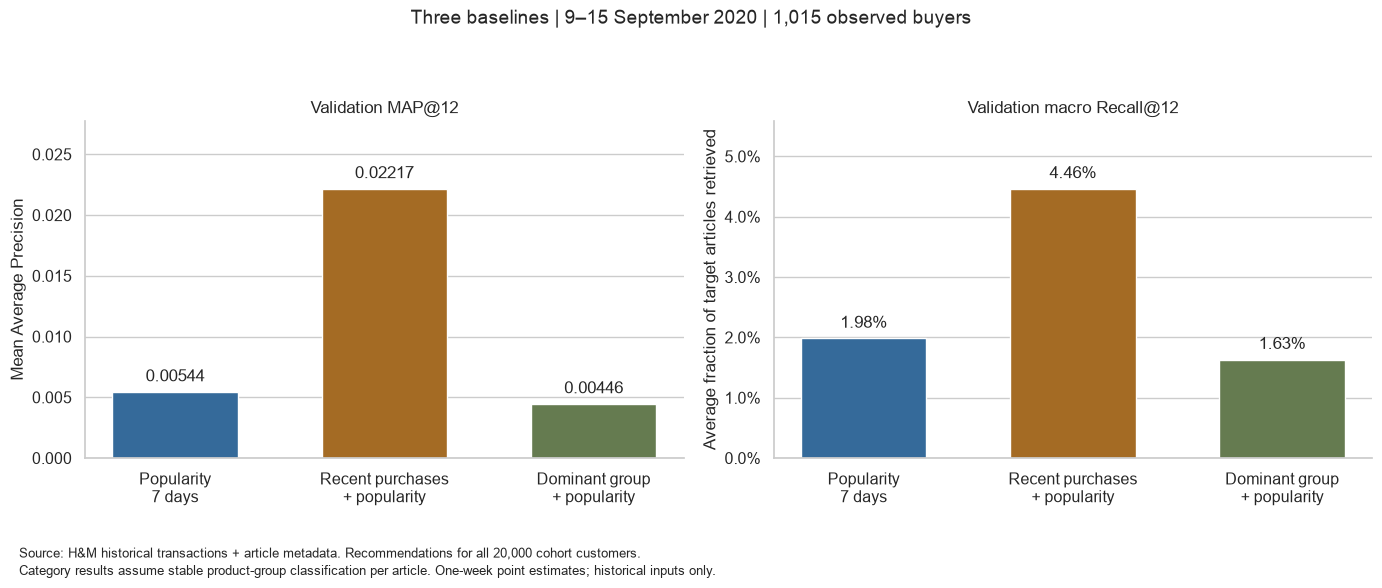

In [43]:
comparison_labels_3 = ['Popularity\n7 days', 'Recent purchases\n+ popularity', 'Dominant group\n+ popularity']
comparison_colours_3 = ["#356A9A", "#A46B24", "#657B50"]
fig_category, axes = plt.subplots(1, 2, figsize=(14, 5.8))
for ax, metric, title in zip(
    axes, ["map_at_12", "recall_at_12"], ["Validation MAP@12", "Validation macro Recall@12"],
):
    values = three_baseline_comparison[metric].tolist()
    ax.bar(comparison_labels_3, values, color=comparison_colours_3, width=0.6)
    ax.set_title(title)
    ax.set_ylim(0, max(max(values) * 1.25, 0.001))
    ax.grid(axis="x", visible=False)
    if metric == "recall_at_12":
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
        bar_labels = [f"{value:.2%}" for value in values]
        ax.set_ylabel("Average fraction of target articles retrieved")
    else:
        bar_labels = [f"{value:.5f}" for value in values]
        ax.set_ylabel("Mean Average Precision")
    ax.bar_label(ax.containers[0], labels=bar_labels, padding=5)

sns.despine(fig=fig_category)
fig_category.suptitle(
    f"Three baselines | 9–15 September 2020 | {n_with_target:,} observed buyers",
    fontsize=14, y=0.99,
)
fig_category.tight_layout(rect=(0, 0.1, 1, 0.93))
fig_category.text(
    0.02, 0.045,
    "Source: H&M historical transactions + article metadata. Recommendations for all 20,000 cohort customers.",
    fontsize=9,
)
fig_category.text(
    0.02, 0.015,
    "Category results assume stable product-group classification per article. One-week point estimates; historical inputs only.",
    fontsize=9,
)
plt.show()

### Interpretation

A reference execution of all 43 code cells in a fresh Python process on the documented source files produced:

- All 105,542 article metadata keys are unique; all observed historical article references match. Metadata joins preserve counts and row grain.
- The 10,667 historical cohort customers produce 30,773 customer–group pairs. Seventeen product groups have observed global purchases in the seven-day popularity window.
- The category rule issues twelve distinct recommendations to each of 20,000 cohort customers: 128,001 recommendation rows are group-sourced and 111,999 are global fallback.
- Category validation MAP@12 = 0.004458753, below global popularity (0.005442630) and recent purchases (0.022168303).
- Category macro Recall@12 = 1.6325%, compared with 1.9836% and 4.4635% respectively.
- The category method retrieves 47 customer–article target pairs for 44 buyers, compared with 57/54 for global popularity and 111/89 for recent purchases. The metric population remains the same 1,015 buyers.
- Compared with global popularity, category AP improves for 35 customers, ties for 948 and decreases for 32; the mean AP difference is negative (-0.000983877). Counting wins and losses alone does not account for their magnitudes.
- For all 187 observed buyers without 180-day history, all three methods have identical scores, as required by fallback.

**Decision:** retain recent purchases with popularity fallback as the best of the three evaluated methods according to validation MAP@12. Do not replace it with this category rule. The dominant-group variant does not improve either MAP or macro Recall over global popularity on this week. This does not establish that category features, multi-group approaches or category-derived candidates are unhelpful.

Independent dictionary-based aggregation reproduces all historical customer-group counts, and a separate relational recommendation–target join reproduces every category AP, recall and hit count.

The observation tests one explicit dominant-group rule, not the predictive value of all category features or alternative mixtures of groups. `group_share` and category popularity remain useful candidate-generation or feature inputs to evaluate later.

Results are conditional on the unverified historical stability of article product-group metadata. One validation week does not establish statistical significance or future business impact. Local-test outcomes remain uninspected.

The saved section 7 outputs agree with these reference observations. The next section measures candidate retrieval separately from final recommendation ranking.

## 8. Candidate Generation and Coverage

### 8.1. Separate retrieval from final ranking

Candidate generation selects up to 300 plausible articles per customer before a future learned ranker chooses twelve. List order here records deterministic construction; it is not an evaluated recommendation ranking or a fitted model score.

**Initial policy, declared before measuring coverage:**

1. Add up to 100 distinct personal-history articles, latest purchase first (180-day history).
2. Add up to 100 distinct recently popular articles in the dominant historical product group (seven-day global counts).
3. Fill from the global popularity order until 300 distinct candidates are present.

Deduplicate across sources. The 100/100 limits bound source proposals, not necessarily their newly added article counts. Overlapping articles consume one final slot. The global source supplies at least 100 new slots under this contract, and can supply more if earlier sources are sparse or overlap.

The pool preserves all twelve recommendations from each existing baseline, so those rankings remain possible within the retrieved set. Customers without history receive global top 300. The source windows and product-group stability assumption remain unchanged.

These limits are initial choices, not measured optima. Generation uses no target articles or target-derived flags. Never insert missed validation purchases into the pool after evaluation.

In [44]:
HISTORY_CANDIDATE_LIMIT = 100
CATEGORY_CANDIDATE_LIMIT = 100

if not TOP_K <= HISTORY_CANDIDATE_LIMIT:
    raise ValueError("The history quota must preserve the existing top-k baseline.")
if not TOP_K <= CATEGORY_CANDIDATE_LIMIT:
    raise ValueError("The category quota must preserve the existing top-k baseline.")
if HISTORY_CANDIDATE_LIMIT + CATEGORY_CANDIDATE_LIMIT > MAX_CANDIDATES:
    raise ValueError("Source limits must leave room within the candidate budget.")

global_candidate_order = validation_popularity.head(MAX_CANDIDATES)["article_id"].tolist()
if len(global_candidate_order) != MAX_CANDIDATES:
    raise ValueError("Global history must supply enough distinct fallback candidates.")

history_candidate_orders = (
    customer_article_history.sort_values(
        ["customer_id", "last_purchase_date", "article_id"], ascending=[True, False, True]
    ).groupby("customer_id", sort=False).head(HISTORY_CANDIDATE_LIMIT)
    .groupby("customer_id")["article_id"].agg(list).to_dict()
)
category_candidate_orders = (
    category_popularity.sort_values(
        ["product_group_name", "transaction_rows", "article_id"], ascending=[True, False, True]
    ).groupby("product_group_name", sort=False).head(CATEGORY_CANDIDATE_LIMIT)
    .groupby("product_group_name")["article_id"].agg(list).to_dict()
)
dominant_group_by_customer = preferred_groups.set_index("customer_id")["product_group_name"].to_dict()

pd.DataFrame([{
    "candidate_budget": MAX_CANDIDATES,
    "history_source_limit": HISTORY_CANDIDATE_LIMIT,
    "category_source_limit": CATEGORY_CANDIDATE_LIMIT,
    "global_source": f"top {MAX_CANDIDATES} from existing {POPULARITY_DAYS}-day popularity",
}])

,candidate_budget,history_source_limit,category_source_limit,global_source
0,300,100,100,top 300 from existing 7-day popularity


### 8.2. Build a deterministic, duplicate-free union

The helper receives source lists that have already been filtered to the cutoff. It does not receive targets or customer eligibility flags.

Audit counts allocate each candidate to the **first source that adds it**. These counts sum to the final pool size. They are not exclusive source-membership features: an article added through history may also occur in category and global retrieval lists. Preserve multi-source flags separately when constructing model features.

In [45]:
def combine_candidate_sources(
    history_articles,
    category_articles,
    global_articles,
    *,
    budget: int,
    history_limit: int,
    category_limit: int,
) -> tuple[list, dict]:
    """Union bounded historical sources, then fill globally without target inputs."""
    if budget <= 0 or min(history_limit, category_limit) < 0:
        raise ValueError("Budget must be positive and source limits nonnegative.")
    if history_limit + category_limit > budget:
        raise ValueError("Source limits exceed the candidate budget.")
    global_order = list(dict.fromkeys(global_articles))[:budget]
    if len(global_order) < budget:
        raise ValueError("Global fallback must supply at least budget distinct articles.")
    source_orders = [
        ("history_added", list(dict.fromkeys(history_articles))[:history_limit]),
        ("category_added", list(dict.fromkeys(category_articles))[:category_limit]),
        ("global_added", global_order),
    ]
    chosen, seen, audit = [], set(), {}
    for source_name, articles in source_orders:
        before = len(chosen)
        for article_id in articles:
            if len(chosen) == budget:
                break
            if article_id not in seen:
                chosen.append(article_id)
                seen.add(article_id)
        audit[source_name] = len(chosen) - before
    return chosen, audit

### 8.3. Test source limits, overlap and cold-history fallback

Use a six-article budget with two history proposals and two category proposals. Deduplicate source lists before truncating them. Expected mixed pool: `[a,b,x,c,d,e]`; the overlap b contributes only once. Disabling categories must produce `[a,b,c,d,e,f]`. Source counts describe first additions, not all possible origins.

In [46]:
fixture_global_candidates = ["c", "d", "e", "f", "g", "h", "i"]
fixture_mixed_pool, fixture_mixed_audit = combine_candidate_sources(
    ["a", "a", "b", "later_history"], ["b", "x", "x", "later_category"],
    fixture_global_candidates, budget=6, history_limit=2, category_limit=2,
)
fixture_no_category, _ = combine_candidate_sources(
    ["a", "b"], [], fixture_global_candidates,
    budget=6, history_limit=2, category_limit=0,
)
fixture_cold_pool, _ = combine_candidate_sources(
    [], [], fixture_global_candidates, budget=6, history_limit=2, category_limit=2,
)
invalid_candidate_inputs_rejected = []
for kwargs in [
    {"budget": 6, "history_limit": 4, "category_limit": 3},
    {"budget": 8, "history_limit": 2, "category_limit": 2},
    {"budget": 6, "history_limit": -1, "category_limit": 2},
]:
    try:
        combine_candidate_sources([], [], fixture_global_candidates, **kwargs)
    except ValueError:
        invalid_candidate_inputs_rejected.append(True)
    else:
        invalid_candidate_inputs_rejected.append(False)

candidate_fixture_checks = pd.Series({
    "source_limits_and_duplicate_removal_match_expected_pool": fixture_mixed_pool == ["a", "b", "x", "c", "d", "e"],
    "first_source_audit_counts_reconcile": fixture_mixed_audit == {"history_added": 2, "category_added": 1, "global_added": 3},
    "category_ablation_preserves_budget": fixture_no_category == ["a", "b", "c", "d", "e", "f"],
    "no_history_uses_global_top_budget": fixture_cold_pool == fixture_global_candidates[:6],
    "invalid_limits_and_insufficient_fallback_are_rejected": all(invalid_candidate_inputs_rejected),
}, name="passed")
if not candidate_fixture_checks.all():
    raise ValueError("Candidate-generation fixture checks failed.")
candidate_fixture_checks.to_frame()

,passed
source_limits_and_duplicate_removal_match_expected_pool,True
first_source_audit_counts_reconcile,True
category_ablation_preserves_budget,True
no_history_uses_global_top_budget,True
invalid_limits_and_insufficient_fallback_are_rejected,True


### 8.4. Generate candidates for all 20,000 customers

Keep one list per customer in a dictionary. At 300 candidates each, the pool represents six million customer–article pairs; do not materialise that whole table just to measure retrieval coverage. This section retains only the dictionary and a small customer-level audit table. Feature preparation can later process customer batches.

Only source lists and fixed cohort IDs enter this generation loop. Category results remain conditional on the metadata-stability assumption.

In [47]:
candidate_pools = {}
candidate_audit_rows = []
for customer_id in cohort_ids:
    group = dominant_group_by_customer.get(customer_id)
    pool, audit = combine_candidate_sources(
        history_candidate_orders.get(customer_id, []),
        category_candidate_orders.get(group, []),
        global_candidate_order,
        budget=MAX_CANDIDATES,
        history_limit=HISTORY_CANDIDATE_LIMIT,
        category_limit=CATEGORY_CANDIDATE_LIMIT,
    )
    candidate_pools[customer_id] = pool
    candidate_audit_rows.append({"customer_id": customer_id, "candidate_count": len(pool), **audit})
candidate_generation_audit = pd.DataFrame(candidate_audit_rows)

candidate_generation_checks = pd.Series({
    "covers_the_fixed_cohort": set(candidate_pools) == set(cohort_ids),
    "every_customer_has_300_candidates": candidate_generation_audit["candidate_count"].eq(MAX_CANDIDATES).all(),
    "every_pool_contains_distinct_articles": all(len(pool) == len(set(pool)) for pool in candidate_pools.values()),
    "source_additions_sum_to_pool_size": candidate_generation_audit[["history_added", "category_added", "global_added"]].sum(axis=1).eq(candidate_generation_audit["candidate_count"]).all(),
    "no_history_receives_global_top_300": all(candidate_pools[customer_id] == global_candidate_order for customer_id in no_history_ids),
    "all_three_baseline_lists_remain_possible": all(
        set(baseline_article_ids + personal_recommendation_lists[customer_id] + category_recommendation_lists[customer_id]).issubset(set(pool))
        for customer_id, pool in candidate_pools.items()
    ),
}, name="passed")
if not candidate_generation_checks.all():
    raise ValueError("Real candidate-generation checks failed.")
candidate_generation_checks.to_frame()

,passed
covers_the_fixed_cohort,True
every_customer_has_300_candidates,True
every_pool_contains_distinct_articles,True
source_additions_sum_to_pool_size,True
no_history_receives_global_top_300,True
all_three_baseline_lists_remain_possible,True


### 8.5. Define coverage and diagnostic ranking ceilings

For a nonempty distinct target set R and a candidate set C:

- Candidate coverage per customer = `len(R ∩ C) / len(R)`.
- **Micro coverage** = all covered target pairs / all target pairs, retaining all targets in the denominator.
- **Macro coverage** = equal-weight mean of customer-level coverage over the same 1,015 observed buyers.
- Oracle Recall@12 = `min(12, len(R ∩ C)) / len(R)`.
- Oracle AP@12 = `min(12, len(R ∩ C)) / min(12, len(R))`.

The oracle ceilings assume a hypothetical perfect ranking that places covered relevant articles first. They use labels for diagnosis only; they are not model predictions, measured MAP@12 performance or deployable recommendation rules.

Pool order does not affect coverage. Never remove unreachable targets or insert missed target articles into evaluation candidates. Customers without targets still receive candidates but remain excluded from these target-based metrics under the existing protocol.

In [48]:
def score_candidate_coverage(relevant_articles, candidates, *, k: int) -> dict:
    """Measure retrieval and label-aware ranking ceilings without changing candidates."""
    relevant = set(relevant_articles)
    if not relevant or k <= 0:
        raise ValueError("Coverage requires nonempty targets and a positive k.")
    candidate_set = set(candidates)
    if len(candidate_set) != len(candidates):
        raise ValueError("Candidate lists must contain distinct articles.")
    n_covered = len(relevant.intersection(candidate_set))
    maximum_top_k_hits = min(k, n_covered)
    return {
        "n_target_articles": len(relevant),
        "n_covered": n_covered,
        "candidate_coverage": n_covered / len(relevant),
        "oracle_recall_at_k": maximum_top_k_hits / len(relevant),
        "oracle_ap_at_k": maximum_top_k_hits / min(k, len(relevant)),
    }


fixture_coverage = score_candidate_coverage({"a", "b", "c", "d"}, ["a", "b", "x"], k=2)
fixture_unreachable = score_candidate_coverage({"a", "missing"}, ["a", "x"], k=2)
coverage_fixture_checks = pd.Series({
    "all_target_articles_remain_in_denominator": fixture_coverage["candidate_coverage"] == fixture_unreachable["candidate_coverage"] == 0.5,
    "oracle_ap_uses_declared_map_denominator": fixture_coverage["oracle_ap_at_k"] == 1,
    "oracle_recall_retains_full_target_denominator": fixture_coverage["oracle_recall_at_k"] == 0.5,
    "candidate_order_does_not_change_coverage": fixture_coverage == score_candidate_coverage({"a", "b", "c", "d"}, ["x", "b", "a"], k=2),
    "no_covered_targets_produces_zero_coverage": score_candidate_coverage({"missing"}, ["a", "x"], k=2)["candidate_coverage"] == 0,
}, name="passed")
if not coverage_fixture_checks.all():
    raise ValueError("Coverage fixture checks failed.")
coverage_fixture_checks.to_frame()

,passed
all_target_articles_remain_in_denominator,True
oracle_ap_uses_declared_map_denominator,True
oracle_recall_retains_full_target_denominator,True
candidate_order_does_not_change_coverage,True
no_covered_targets_produces_zero_coverage,True


### 8.6. Compare retrieval sources at the same 300-candidate budget

Compare global top 300, history plus global fill, and the declared mixed pool. Construct the alternate history-only union only for evaluation buyers to avoid duplicating the complete cohort pool in memory. All three policies generate candidates from historical sources only; labels are used afterward for coverage.

A weak standalone category recommendation rule may still contribute useful candidates, or may displace more useful global candidates under a fixed budget. This comparison measures that trade-off without assuming its direction.

In [49]:
candidate_evaluation_rows = []
for customer_id, relevant in validation_relevant_articles.items():
    history_pool, _ = combine_candidate_sources(
        history_candidate_orders.get(customer_id, []), [], global_candidate_order,
        budget=MAX_CANDIDATES, history_limit=HISTORY_CANDIDATE_LIMIT, category_limit=0,
    )
    for policy, pool in [
        ("global_300", global_candidate_order),
        ("history_then_global_300", history_pool),
        ("history_category_then_global_300", candidate_pools[customer_id]),
    ]:
        candidate_evaluation_rows.append({
            "policy": policy,
            "customer_id": customer_id,
            "candidate_count": len(pool),
            **score_candidate_coverage(relevant, pool, k=TOP_K),
        })
candidate_customer_coverage = pd.DataFrame(candidate_evaluation_rows)

candidate_coverage_comparison = candidate_customer_coverage.groupby("policy", sort=False).agg(
    evaluated_customers=("customer_id", "size"),
    candidates_per_customer=("candidate_count", "mean"),
    covered_target_pairs=("n_covered", "sum"),
    total_target_pairs=("n_target_articles", "sum"),
    macro_candidate_coverage=("candidate_coverage", "mean"),
    oracle_map_at_12=("oracle_ap_at_k", "mean"),
    oracle_recall_at_12=("oracle_recall_at_k", "mean"),
)
candidate_coverage_comparison["micro_candidate_coverage"] = (
    candidate_coverage_comparison["covered_target_pairs"]
    / candidate_coverage_comparison["total_target_pairs"]
)
if not candidate_coverage_comparison["evaluated_customers"].eq(n_with_target).all():
    raise ValueError("Candidate policies must use identical metric population sizes.")
if not candidate_coverage_comparison["total_target_pairs"].eq(len(validation_targets)).all():
    raise ValueError("Candidate coverage must retain every target pair.")
candidate_coverage_comparison

,evaluated_customers,candidates_per_customer,covered_target_pairs,total_target_pairs,macro_candidate_coverage,oracle_map_at_12,oracle_recall_at_12,micro_candidate_coverage
policy,,,,,,,,
global_300,1015,300.0,613,3073,0.206682,0.207365,0.206682,0.199479
history_then_global_300,1015,300.0,679,3073,0.233801,0.234564,0.233801,0.220957
history_category_then_global_300,1015,300.0,680,3073,0.230872,0.231570,0.230872,0.221282


### 8.7. Inspect history segments, missing targets and the oracle ceiling

The generation audit covers all 20,000 customers. Coverage segments cover only the 1,015 metric-eligible customers, using pre-cutoff history flags. An uncovered target stays in every denominator; it records a retrieval miss, not an article to add to the pool.

Because the mixed pool contains the three original baseline lists, its per-customer oracle AP must be at least each baseline's achieved AP. This is a consistency check on the diagnostic ceiling, not a model-quality claim.

In [50]:
mixed_customer_coverage = candidate_customer_coverage.loc[
    candidate_customer_coverage["policy"].eq("history_category_then_global_300")
].merge(
    customer_history_summary[["customer_id", "has_history"]],
    on="customer_id", how="left", validate="one_to_one",
)
if mixed_customer_coverage["has_history"].isna().any():
    raise ValueError("Coverage segments must retain historical flags for every evaluated customer.")

candidate_segment_coverage = mixed_customer_coverage.groupby("has_history").agg(
    evaluated_customers=("customer_id", "size"),
    covered_target_pairs=("n_covered", "sum"),
    total_target_pairs=("n_target_articles", "sum"),
    macro_candidate_coverage=("candidate_coverage", "mean"),
)
candidate_segment_coverage["micro_candidate_coverage"] = (
    candidate_segment_coverage["covered_target_pairs"] / candidate_segment_coverage["total_target_pairs"]
)
candidate_segment_coverage.index = candidate_segment_coverage.index.map({False: "No 180-day history", True: "Has 180-day history"})

oracle_by_customer = mixed_customer_coverage.set_index("customer_id")["oracle_ap_at_k"]
for scores in [baseline_customer_scores, personal_customer_scores, category_customer_scores]:
    achieved_ap = scores.set_index("customer_id")["ap_at_k"]
    if not (oracle_by_customer.reindex(achieved_ap.index) + 1e-12).ge(achieved_ap).all():
        raise ValueError("An oracle ceiling cannot be below an achievable baseline AP.")

candidate_generation_summary = pd.Series({
    "recommendation_population": len(candidate_pools),
    "candidates_per_customer": MAX_CANDIDATES,
    "implicit_customer_article_pairs": int(candidate_generation_audit["candidate_count"].sum()),
    "history_first_additions": int(candidate_generation_audit["history_added"].sum()),
    "category_first_additions": int(candidate_generation_audit["category_added"].sum()),
    "global_first_additions": int(candidate_generation_audit["global_added"].sum()),
    "uncovered_validation_target_pairs": int(mixed_customer_coverage["n_target_articles"].sum() - mixed_customer_coverage["n_covered"].sum()),
}, name="value").to_frame()
print(candidate_generation_summary.to_string())
candidate_segment_coverage

                                     value
recommendation_population            20000
candidates_per_customer                300
implicit_customer_article_pairs    6000000
history_first_additions              98125
category_first_additions           1061367
global_first_additions             4840508
uncovered_validation_target_pairs     2393


,evaluated_customers,covered_target_pairs,total_target_pairs,macro_candidate_coverage,micro_candidate_coverage
has_history,,,,,
No 180-day history,187,122,594,0.216869,0.205387
Has 180-day history,828,558,2479,0.234035,0.225091


### 8.8. Visualise retrieval coverage at a fixed budget

Left: micro coverage across all distinct customer–article targets. Right: equal-weight customer-average coverage. All policies have 300 candidates and the same observed buyers. These are retrieval diagnostics, not the MAP/Recall of final twelve-article recommendations.

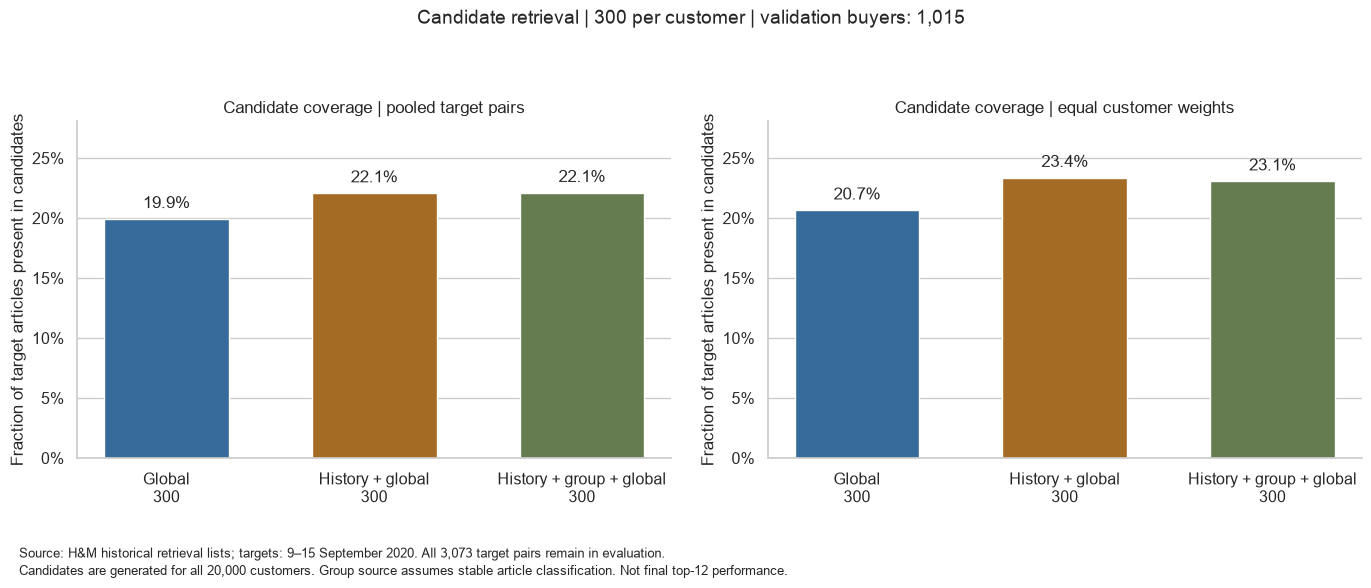

In [51]:
candidate_policy_labels = ['Global\n300', 'History + global\n300', 'History + group + global\n300']
candidate_plot_limit = max(candidate_coverage_comparison[["micro_candidate_coverage", "macro_candidate_coverage"]].max().max() * 1.2, 0.01)
fig_candidates, axes = plt.subplots(1, 2, figsize=(14, 5.8))
for ax, metric, title in zip(
    axes,
    ["micro_candidate_coverage", "macro_candidate_coverage"],
    ["Candidate coverage | pooled target pairs", "Candidate coverage | equal customer weights"],
):
    values = candidate_coverage_comparison[metric].tolist()
    ax.bar(candidate_policy_labels, values, color=["#356A9A", "#A46B24", "#657B50"], width=0.6)
    ax.set_title(title)
    ax.set_ylim(0, candidate_plot_limit)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set_ylabel("Fraction of target articles present in candidates")
    ax.grid(axis="x", visible=False)
    ax.bar_label(ax.containers[0], labels=[f"{value:.1%}" for value in values], padding=5)

sns.despine(fig=fig_candidates)
fig_candidates.suptitle(
    f"Candidate retrieval | 300 per customer | validation buyers: {n_with_target:,}",
    fontsize=14, y=0.99,
)
fig_candidates.tight_layout(rect=(0, 0.1, 1, 0.93))
fig_candidates.text(
    0.02, 0.045,
    "Source: H&M historical retrieval lists; targets: 9–15 September 2020. All 3,073 target pairs remain in evaluation.",
    fontsize=9,
)
fig_candidates.text(
    0.02, 0.015,
    "Candidates are generated for all 20,000 customers. Group source assumes stable article classification. Not final top-12 performance.",
    fontsize=9,
)
plt.show()

### Interpretation

A reference execution of all 51 code cells in a fresh Python process on the documented source files produced:

- Exactly 300 distinct candidates for every one of 20,000 cohort customers: six million implicit customer–article pairs, retained as lists rather than a materialised full feature table.
- First-source additions: 98,125 history, 1,061,367 category, 4,840,508 global fill. These counts sum to six million and do not represent exclusive source-membership flags.
- Global top 300 covers 613 / 3,073 target pairs (micro 19.9479%; macro 20.6682%).
- History plus global fill covers 679 / 3,073 (micro 22.0957%; macro 23.3801%).
- History plus category plus global fill covers 680 / 3,073 (micro 22.1282%; macro 23.0872%).
- The mixed pool leaves 2,393 target pairs outside candidates; all remain in metric denominators. No target was inserted after generation.
- With a fixed budget, category retrieval gives a net gain of one covered pair relative to history/global but lowers equal-weight customer-average coverage. Its value is not established by a pooled-count gain alone. Keep the simpler ablation available for future ranking comparisons.
- All three original baseline rankings fit inside the mixed pool. Customers without history receive global top 300.
- Under this fixed mixed pool and these targets, oracle MAP@12 = 0.231569815 and oracle Recall@12 = 0.230872190. These are label-aware diagnostic ceilings, not trained-model results.

Retain the declared mixed pool as the initial candidate policy, with the history/global alternative recorded. The mixed policy is not uniformly superior and the quotas have not been optimised. Final ranking MAP@12 and broader temporal validation remain to assess.

Independent target-row list membership reproduces all mixed-pool covered counts. Every generated article belongs to the pre-cutoff historical source universe, and all policies use identical evaluation-customer sets.

The oracle metrics are label-aware theoretical ceilings on this candidate set. A future ranker may perform far below them. Keep generation and feature computation independent of target membership; labels are attached only afterward for training or evaluation under the temporal protocol.

Section 8 must be executed before this feature pilot. Its reference results above were verified in a fresh Python process; the next section consumes the generated historical candidate lists.

## 9. Historical Features — Contract and Pilot Batch

### 9.1. Define feature meaning before training

A feature row represents one `(customer_id, article_id, cutoff)` prediction opportunity. Its inputs must precede that cutoff. The pilot uses the first 100 fixed-cohort IDs, independently of future purchases: 100 × 300 = 30,000 rows.

Define seventeen numeric/boolean features covering customer activity, article popularity, customer–group affinity, customer–article interaction and retrieval-source membership. The current windows remain 180 days for customer/interaction history and seven days for global popularity.

Identifiers, cutoff and product-group labels are audit/join fields outside `FEATURE_COLUMNS`. Validation labels, coverage, oracle scores and future purchase flags are not features. No scaling, categorical encoding, statistical imputation or fitted transformation is performed here; future learned preprocessing must be fitted on training cutoffs only.

Zeros mean no observed qualifying rows in a fully observed source window. Missing recency/rank means no corresponding observed event/ranking, not a purchase today or a numerical rank of zero. Product-group usage retains the documented stability assumption.

In [52]:
feature_contract = pd.DataFrame(
    [
        ('customer_history_rows', 'customer', '0', 'Observed source purchase rows in customer history'),
        ('customer_distinct_articles', 'customer', '0', 'Distinct purchased article IDs in customer history'),
        ('customer_recency_days', 'customer', 'NaN without observed history', 'Days since last observed customer purchase'),
        ('customer_has_history', 'customer', 'False', 'Any observed customer purchase in the history window'),
        ('article_recent_rows', 'article', '0 if absent from recent purchases', 'Global source purchase rows for this article in the recent window'),
        ('article_recent_rank', 'article', 'NaN if absent from recent purchases', 'Global recent popularity rank; count descending, ID ascending'),
        ('customer_group_rows', 'customer-group', '0', 'Customer historical purchase rows in the candidate product group'),
        ('customer_group_share', 'customer-group', '0', 'Group rows divided by all customer historical rows'),
        ('customer_article_rows', 'customer-article', '0', 'Customer historical purchase rows for this article'),
        ('customer_article_recency_days', 'customer-article', 'NaN without observed purchase', 'Days since this customer last bought this article'),
        ('has_purchased_article', 'customer-article', 'False', 'Any observed purchase of this article by this customer'),
        ('from_history', 'retrieval', 'False', 'Article belongs to the bounded history retrieval proposal'),
        ('from_category', 'retrieval', 'False', 'Article belongs to the bounded dominant-group retrieval proposal'),
        ('from_global', 'retrieval', 'False', 'Article belongs to global top candidate-budget retrieval proposal'),
        ('history_source_rank', 'retrieval', 'NaN outside bounded source', 'Position within the bounded history retrieval proposal'),
        ('category_source_rank', 'retrieval', 'NaN outside bounded source', 'Position within the bounded dominant-group proposal'),
        ('n_retrieval_sources', 'retrieval', '0 for articles outside every source', 'Number of retrieval proposals containing the article'),
    ],
    columns=["feature", "family", "missing_policy", "meaning"],
)
FEATURE_COLUMNS = feature_contract["feature"].tolist()
PILOT_CUSTOMERS = 100

feature_contract

,feature,family,missing_policy,meaning
0,customer_history_rows,customer,0,Observed source purchase rows in customer history
1,customer_distinct_articles,customer,0,Distinct purchased article IDs in customer his...
2,customer_recency_days,customer,NaN without observed history,Days since last observed customer purchase
3,customer_has_history,customer,False,Any observed customer purchase in the history ...
4,article_recent_rows,article,0 if absent from recent purchases,Global source purchase rows for this article i...
5,article_recent_rank,article,NaN if absent from recent purchases,Global recent popularity rank; count descendin...
6,customer_group_rows,customer-group,0,Customer historical purchase rows in the candi...
7,customer_group_share,customer-group,0,Group rows divided by all customer historical ...
8,customer_article_rows,customer-article,0,Customer historical purchase rows for this art...
9,customer_article_recency_days,customer-article,NaN without observed purchase,Days since this customer last bought this article


### 9.2. Prepare reusable historical lookup tables

All tables share one explicit cutoff context. Recompute them at each historical prediction cutoff later; do not reuse validation popularity at earlier dates. The popularity table has no dates left, so its cutoff safety relies on the existing upstream aggregation and its declared window.

Validate customer–article uniqueness, positive retained counts and historical dates. Reuse the existing category aggregation. Restrict article lookups to IDs observed in the supplied historical sources; the unversioned metadata snapshot does not create future catalogue candidates.

Retrieve source ranks independently of the audit's first-addition counts: an article can belong to several proposal lists.

In [53]:
def prepare_feature_tables(
    customer_ids, history, popularity, metadata, *, cutoff, history_days,
    popularity_days, history_limit, category_limit, global_limit,
) -> dict:
    """Prepare historical lookups for one declared prediction cutoff."""
    cutoff = pd.Timestamp(cutoff)
    if history_days <= 0 or popularity_days <= 0 or min(history_limit, category_limit, global_limit) <= 0:
        raise ValueError("Feature windows and retrieval limits must be positive.")
    if not customer_ids.is_unique or history.duplicated(["customer_id", "article_id"]).any():
        raise ValueError("Customer IDs and historical customer–article keys must be unique.")
    if not history["customer_id"].isin(customer_ids).all() or not history["history_transaction_rows"].gt(0).all():
        raise ValueError("History must contain known customers and positive observed counts.")
    if not interval_mask(history["last_purchase_date"], cutoff - pd.Timedelta(days=history_days), cutoff).all():
        raise ValueError("History contains dates outside the declared pre-cutoff interval.")

    affinities, dominant, grouped_popularity = build_category_tables(history, popularity, metadata)
    customer_observed = history.groupby("customer_id", as_index=False).agg(
        customer_history_rows=("history_transaction_rows", "sum"),
        customer_distinct_articles=("article_id", "size"),
        last_purchase_date=("last_purchase_date", "max"),
    )
    customers = pd.DataFrame({"customer_id": customer_ids}).merge(
        customer_observed, on="customer_id", how="left", validate="one_to_one",
    ).merge(
        dominant[["customer_id", "product_group_name"]].rename(columns={"product_group_name": "dominant_product_group"}),
        on="customer_id", how="left", validate="one_to_one",
    )
    customers["customer_recency_days"] = (cutoff - customers["last_purchase_date"]).dt.days
    customers = customers.drop(columns="last_purchase_date")

    recent = popularity.sort_values(["transaction_rows", "article_id"], ascending=[False, True]).reset_index(drop=True)
    recent = recent.rename(columns={"transaction_rows": "article_recent_rows"})
    recent["article_recent_rank"] = range(1, len(recent) + 1)
    grouped_popularity = grouped_popularity.copy()
    grouped_popularity["_group_popularity_rank"] = grouped_popularity.groupby("product_group_name").cumcount() + 1
    observed_ids = pd.concat([history["article_id"], popularity["article_id"]], ignore_index=True).drop_duplicates()
    articles = attach_product_groups(observed_ids.to_frame(name="article_id"), metadata).merge(
        recent, on="article_id", how="left", validate="one_to_one",
    ).merge(
        grouped_popularity[["article_id", "_group_popularity_rank"]],
        on="article_id", how="left", validate="one_to_one",
    )
    groups = affinities[["customer_id", "product_group_name", "group_transaction_rows", "group_share"]].rename(
        columns={"group_transaction_rows": "customer_group_rows", "group_share": "customer_group_share"}
    )
    interactions = history.sort_values(
        ["customer_id", "last_purchase_date", "article_id"], ascending=[True, False, True],
    ).copy()
    interactions["_history_rank"] = interactions.groupby("customer_id").cumcount() + 1
    interactions["history_source_rank"] = interactions["_history_rank"].where(interactions["_history_rank"].le(history_limit))
    interactions["customer_article_recency_days"] = (cutoff - interactions["last_purchase_date"]).dt.days
    interactions = interactions.rename(columns={"history_transaction_rows": "customer_article_rows"})
    interactions = interactions[["customer_id", "article_id", "customer_article_rows", "customer_article_recency_days", "history_source_rank"]]
    return {
        "cutoff": cutoff, "history_days": history_days, "popularity_days": popularity_days,
        "category_limit": category_limit, "global_limit": global_limit,
        "customers": customers, "articles": articles, "groups": groups, "interactions": interactions,
    }

### 9.3. Join one candidate batch and preserve feature semantics

Accept only the three prediction keys. Reject unexpected columns, duplicate pairs, unknown source IDs and mismatched cutoff contexts. Each join must preserve the candidate-row grain.

Fill observed-count/share absences with zero only after reference integrity is established. Keep absent recencies and ranks missing. Retrieval flags are nonexclusive: `n_retrieval_sources` can be two or three, unlike the earlier first-addition audit.

In [54]:
def build_candidate_feature_batch(candidate_pairs: pd.DataFrame, tables: dict) -> pd.DataFrame:
    """Construct historical features without labels, fitted transforms or target inputs."""
    keys = ["customer_id", "article_id", "cutoff"]
    if set(candidate_pairs.columns) != set(keys) or candidate_pairs.empty:
        raise ValueError("A nonempty batch must contain exactly customer_id, article_id and cutoff.")
    if candidate_pairs[keys].isna().any().any() or candidate_pairs.duplicated(keys).any():
        raise ValueError("Prediction keys must be present and unique.")
    if not candidate_pairs["cutoff"].eq(tables["cutoff"]).all():
        raise ValueError("Candidate cutoff differs from historical feature-table context.")
    if not candidate_pairs["customer_id"].isin(tables["customers"]["customer_id"]).all():
        raise ValueError("Candidate batch contains a customer outside the source context.")
    if not candidate_pairs["article_id"].isin(tables["articles"]["article_id"]).all():
        raise ValueError("Candidate article lacks a historical source reference.")

    result = candidate_pairs[keys].reset_index(drop=True).merge(
        tables["customers"], on="customer_id", how="left", validate="many_to_one",
    ).merge(
        tables["articles"], on="article_id", how="left", validate="many_to_one",
    ).merge(
        tables["groups"], on=["customer_id", "product_group_name"], how="left", validate="many_to_one",
    ).merge(
        tables["interactions"], on=["customer_id", "article_id"], how="left", validate="one_to_one",
    )
    for column in [
        "customer_history_rows", "customer_distinct_articles", "article_recent_rows",
        "customer_group_rows", "customer_article_rows",
    ]:
        result[column] = result[column].fillna(0).astype("int64")
    result["customer_group_share"] = result["customer_group_share"].fillna(0).astype("float64")
    result["customer_has_history"] = result["customer_distinct_articles"].gt(0)
    result["has_purchased_article"] = result["customer_article_rows"].gt(0)
    result["from_history"] = result["history_source_rank"].notna()
    result["from_category"] = (
        result["product_group_name"].eq(result["dominant_product_group"]).fillna(False)
        & result["_group_popularity_rank"].le(tables["category_limit"]).fillna(False)
    )
    result["from_global"] = result["article_recent_rank"].le(tables["global_limit"]).fillna(False)
    result["category_source_rank"] = result["_group_popularity_rank"].where(result["from_category"])
    result["n_retrieval_sources"] = result[["from_history", "from_category", "from_global"]].sum(axis=1).astype("int64")
    for column in [
        "customer_recency_days", "article_recent_rank", "customer_article_recency_days",
        "history_source_rank", "category_source_rank",
    ]:
        result[column] = result[column].astype("float64")
    audit_columns = keys + ["product_group_name", "dominant_product_group"]
    if len(result) != len(candidate_pairs):
        raise ValueError("Feature joins changed the candidate-row grain.")
    return result[audit_columns + FEATURE_COLUMNS]

### 9.4. Verify counts, missing values, source overlaps and cutoff protection

The fixture has one historical customer u and one customer without observed history v. Article o was bought historically but has no recent global purchases. Article p belongs to both the dominant-group and global retrieval proposals.

Check known expected feature values rather than merely checking that the function runs. Also reject future-dated history, an evaluation flag inserted into prediction keys, duplicate pairs, unknown article references and a mismatched prediction cutoff.

In [55]:
feature_fixture_ids = pd.Index(["u", "v"], dtype="string")
feature_fixture_history = pd.DataFrame({
    "customer_id": ["u", "u"], "article_id": ["h", "o"],
    "last_purchase_date": pd.to_datetime(["2020-09-08", "2020-09-01"]),
    "history_transaction_rows": [2, 1],
})
feature_fixture_popularity = pd.DataFrame({"article_id": ["q", "p", "h"], "transaction_rows": [30, 20, 10]})
feature_fixture_metadata = pd.DataFrame({"article_id": ["h", "o", "p", "q"], "product_group_name": ["A", "B", "A", "B"]})
feature_fixture_tables = prepare_feature_tables(
    feature_fixture_ids, feature_fixture_history, feature_fixture_popularity, feature_fixture_metadata,
    cutoff=VALIDATION_CUTOFF, history_days=HISTORY_DAYS, popularity_days=POPULARITY_DAYS,
    history_limit=2, category_limit=1, global_limit=2,
)
feature_fixture_pairs = pd.DataFrame({
    "customer_id": ["u", "u", "u", "v"], "article_id": ["h", "o", "p", "p"],
    "cutoff": [VALIDATION_CUTOFF] * 4,
})
feature_fixture = build_candidate_feature_batch(feature_fixture_pairs, feature_fixture_tables).set_index(["customer_id", "article_id"])

invalid_feature_batches = [
    feature_fixture_pairs.assign(has_target_purchase=True),
    feature_fixture_pairs.assign(cutoff=LOCAL_TEST_CUTOFF),
    pd.concat([feature_fixture_pairs, feature_fixture_pairs.iloc[[0]]]),
    feature_fixture_pairs.assign(article_id="unobserved_article"),
]
feature_invalid_inputs_rejected = []
for bad_batch in invalid_feature_batches:
    try:
        build_candidate_feature_batch(bad_batch, feature_fixture_tables)
    except ValueError:
        feature_invalid_inputs_rejected.append(True)
    else:
        feature_invalid_inputs_rejected.append(False)
future_fixture_history = feature_fixture_history.copy()
future_fixture_history.loc[0, "last_purchase_date"] = VALIDATION_CUTOFF
try:
    prepare_feature_tables(
        feature_fixture_ids, future_fixture_history, feature_fixture_popularity, feature_fixture_metadata,
        cutoff=VALIDATION_CUTOFF, history_days=HISTORY_DAYS, popularity_days=POPULARITY_DAYS,
        history_limit=2, category_limit=1, global_limit=2,
    )
except ValueError:
    feature_future_history_rejected = True
else:
    feature_future_history_rejected = False

feature_fixture_checks = pd.Series({
    "historical_customer_counts_and_recency": feature_fixture.loc[("u", "h"), "customer_history_rows"] == 3 and feature_fixture.loc[("u", "h"), "customer_recency_days"] == 1,
    "interaction_counts_and_recency": feature_fixture.loc[("u", "h"), "customer_article_rows"] == 2 and feature_fixture.loc[("u", "h"), "customer_article_recency_days"] == 1,
    "missing_recent_popularity_has_zero_count_and_missing_rank": feature_fixture.loc[("u", "o"), "article_recent_rows"] == 0 and pd.isna(feature_fixture.loc[("u", "o"), "article_recent_rank"]),
    "group_affinity_matches_two_thirds": isclose(feature_fixture.loc[("u", "p"), "customer_group_share"], 2 / 3),
    "no_history_keeps_recency_missing": not feature_fixture.loc[("v", "p"), "customer_has_history"] and pd.isna(feature_fixture.loc[("v", "p"), "customer_recency_days"]),
    "unobserved_interaction_keeps_recency_missing": feature_fixture.loc[("u", "p"), "customer_article_rows"] == 0 and pd.isna(feature_fixture.loc[("u", "p"), "customer_article_recency_days"]),
    "overlapping_sources_are_both_recorded": feature_fixture.loc[("u", "p"), "from_category"] and feature_fixture.loc[("u", "p"), "from_global"] and feature_fixture.loc[("u", "p"), "n_retrieval_sources"] == 2,
    "invalid_batches_are_rejected": all(feature_invalid_inputs_rejected),
    "cutoff_day_history_is_rejected": feature_future_history_rejected,
}, name="passed")
if not feature_fixture_checks.all():
    raise ValueError("Feature fixture checks failed.")
feature_fixture_checks.to_frame()

,passed
historical_customer_counts_and_recency,True
interaction_counts_and_recency,True
missing_recent_popularity_has_zero_count_and_missing_rank,True
group_affinity_matches_two_thirds,True
no_history_keeps_recency_missing,True
unobserved_interaction_keeps_recency_missing,True
overlapping_sources_are_both_recorded,True
invalid_batches_are_rejected,True
cutoff_day_history_is_rejected,True


### 9.5. Build a 100-customer pilot without using future activity

Choose the first cohort IDs in their fixed deterministic order. Include all their candidate articles; do not select customers based on target purchases or choose only successful predictions.

The historical lookup tables are reusable across candidate batches at this cutoff. The pilot creates 30,000 rows rather than materialising all six million feature rows.

In [56]:
feature_tables = prepare_feature_tables(
    cohort_ids, customer_article_history, validation_popularity, article_groups,
    cutoff=VALIDATION_CUTOFF, history_days=HISTORY_DAYS, popularity_days=POPULARITY_DAYS,
    history_limit=HISTORY_CANDIDATE_LIMIT, category_limit=CATEGORY_CANDIDATE_LIMIT,
    global_limit=MAX_CANDIDATES,
)
pilot_customer_ids = cohort_ids[:PILOT_CUSTOMERS]
pilot_candidate_pairs = pd.DataFrame(
    [(customer_id, article_id, VALIDATION_CUTOFF)
     for customer_id in pilot_customer_ids for article_id in candidate_pools[customer_id]],
    columns=["customer_id", "article_id", "cutoff"],
)
feature_batch = build_candidate_feature_batch(pilot_candidate_pairs, feature_tables)

print(f"Pilot customers: {feature_batch['customer_id'].nunique():,}")
print(f"Candidate rows: {len(feature_batch):,}")
print(f"Model features: {len(FEATURE_COLUMNS)}")
feature_batch[FEATURE_COLUMNS].head()

Pilot customers: 100
Candidate rows: 30,000
Model features: 17


,customer_history_rows,customer_distinct_articles,customer_recency_days,customer_has_history,article_recent_rows,article_recent_rank,customer_group_rows,customer_group_share,customer_article_rows,customer_article_recency_days,has_purchased_article,from_history,from_category,from_global,history_source_rank,category_source_rank,n_retrieval_sources
0,0,0,NaN,False,779,1.0,0,0.0,0,NaN,False,False,False,True,NaN,NaN,1
1,0,0,NaN,False,757,2.0,0,0.0,0,NaN,False,False,False,True,NaN,NaN,1
2,0,0,NaN,False,724,3.0,0,0.0,0,NaN,False,False,False,True,NaN,NaN,1
3,0,0,NaN,False,683,4.0,0,0.0,0,NaN,False,False,False,True,NaN,NaN,1
4,0,0,NaN,False,614,5.0,0,0.0,0,NaN,False,False,False,True,NaN,NaN,1


### 9.6. Check the real feature schema and inspect missingness

Missing recencies and source ranks are expected. Count/share/flag features must be defined. Check the temporal ranges, source membership, preserved keys and numeric-only model matrix.

This validates feature computation and semantics; it does not establish predictive usefulness. No labels are attached or used for feature selection, no model parameters are fitted, and no correlations with validation outcomes are explored here.

In [57]:
EXPECTED_MISSING_FEATURES = [
    "customer_recency_days", "article_recent_rank", "customer_article_recency_days",
    "history_source_rank", "category_source_rank",
]
required_features = [column for column in FEATURE_COLUMNS if column not in EXPECTED_MISSING_FEATURES]
feature_batch_checks = pd.Series({
    "pilot_has_expected_pair_count": len(feature_batch) == len(pilot_customer_ids) * MAX_CANDIDATES,
    "prediction_keys_are_preserved": feature_batch[["customer_id", "article_id", "cutoff"]].eq(pilot_candidate_pairs).all().all(),
    "seventeen_numeric_or_boolean_model_features": len(FEATURE_COLUMNS) == 17 and all(pd.api.types.is_numeric_dtype(feature_batch[column]) for column in FEATURE_COLUMNS),
    "required_feature_values_are_present": not feature_batch[required_features].isna().any().any(),
    "no_infinite_feature_values": not feature_batch[FEATURE_COLUMNS].isin([float("inf"), -float("inf")]).any().any(),
    "group_shares_are_valid": feature_batch["customer_group_share"].between(0, 1).all(),
    "customer_recencies_are_strictly_historical": feature_batch["customer_recency_days"].dropna().between(1, HISTORY_DAYS).all(),
    "interaction_recencies_are_strictly_historical": feature_batch["customer_article_recency_days"].dropna().between(1, HISTORY_DAYS).all(),
    "unobserved_interactions_have_missing_recency": feature_batch.loc[~feature_batch["has_purchased_article"], "customer_article_recency_days"].isna().all(),
    "every_candidate_has_a_retrieval_source": feature_batch["n_retrieval_sources"].between(1, 3).all(),
})
if not feature_batch_checks.all():
    failed = feature_batch_checks.index[~feature_batch_checks].tolist()
    raise ValueError(f"Real feature-batch checks failed: {failed}")
print(feature_batch_checks.to_string())

feature_profile = pd.DataFrame({
    "dtype": feature_batch[FEATURE_COLUMNS].dtypes.astype(str),
    "missing_rows": feature_batch[FEATURE_COLUMNS].isna().sum(),
    "missing_share_pct": 100 * feature_batch[FEATURE_COLUMNS].isna().mean(),
})
feature_profile

pilot_has_expected_pair_count                    True
prediction_keys_are_preserved                    True
seventeen_numeric_or_boolean_model_features      True
required_feature_values_are_present              True
no_infinite_feature_values                       True
group_shares_are_valid                           True
customer_recencies_are_strictly_historical       True
interaction_recencies_are_strictly_historical    True
unobserved_interactions_have_missing_recency     True
every_candidate_has_a_retrieval_source           True


,dtype,missing_rows,missing_share_pct
customer_history_rows,int64,0,0.000000
customer_distinct_articles,int64,0,0.000000
customer_recency_days,float64,13500,45.000000
customer_has_history,bool,0,0.000000
article_recent_rows,int64,0,0.000000
article_recent_rank,float64,71,0.236667
customer_group_rows,int64,0,0.000000
customer_group_share,float64,0,0.000000
customer_article_rows,int64,0,0.000000
customer_article_recency_days,float64,29655,98.850000


### 9.7. Visualise overlapping source flags and interaction recency

Both panels describe this 100-customer pilot, not the full cohort. Source-membership counts may sum to more than the row count because flags overlap. The recency histogram is restricted to pairs with an observed purchase in the historical window; other recencies remain missing.

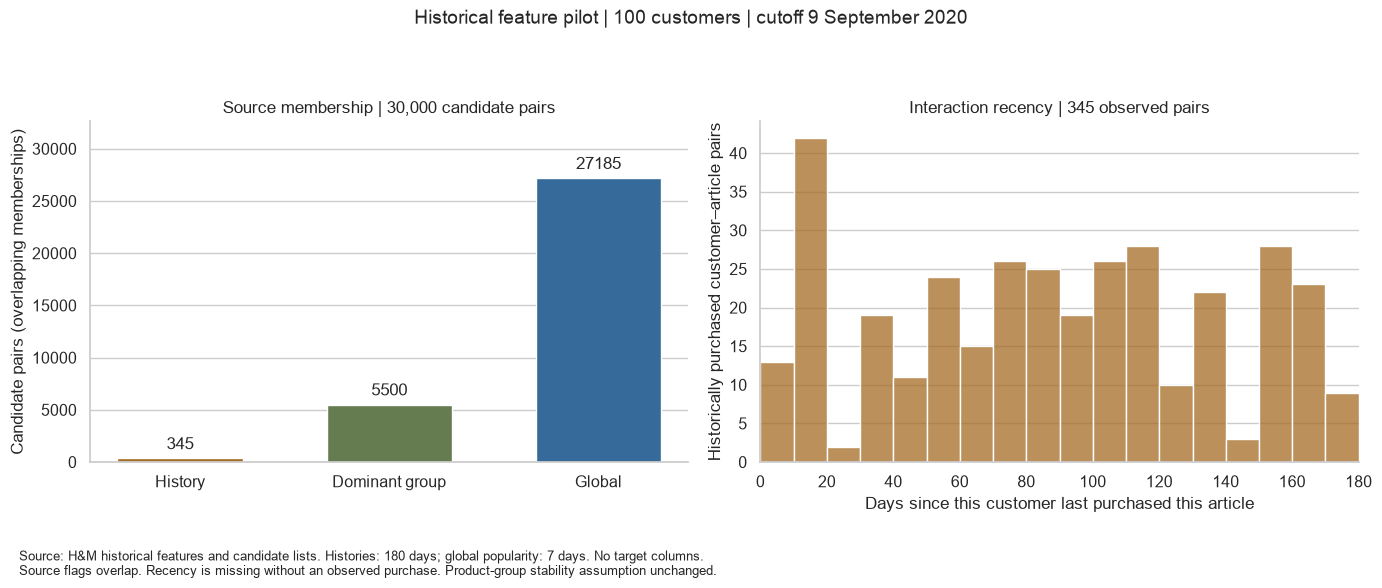

In [58]:
pilot_source_counts = feature_batch[["from_history", "from_category", "from_global"]].sum()
pilot_observed_recencies = feature_batch.loc[
    feature_batch["has_purchased_article"], "customer_article_recency_days"
]
fig_features, axes = plt.subplots(1, 2, figsize=(14, 5.8))
axes[0].bar(
    ["History", "Dominant group", "Global"], pilot_source_counts.values,
    color=["#A46B24", "#657B50", "#356A9A"], width=0.6,
)
axes[0].set_title(f"Source membership | {len(feature_batch):,} candidate pairs")
axes[0].set_ylabel("Candidate pairs (overlapping memberships)")
axes[0].set_ylim(0, max(pilot_source_counts.max() * 1.2, 1))
axes[0].bar_label(axes[0].containers[0], fmt="%.0f", padding=4)
axes[0].grid(axis="x", visible=False)

if not pilot_observed_recencies.empty:
    sns.histplot(
        pilot_observed_recencies, bins=list(range(0, HISTORY_DAYS + 1, 10)),
        color="#A46B24", ax=axes[1],
    )
else:
    axes[1].text(0.5, 0.5, "No observed historical interactions in this pilot", ha="center", transform=axes[1].transAxes)
axes[1].set_title(f"Interaction recency | {len(pilot_observed_recencies):,} observed pairs")
axes[1].set_xlabel("Days since this customer last purchased this article")
axes[1].set_ylabel("Historically purchased customer–article pairs")
axes[1].set_xlim(0, HISTORY_DAYS)
axes[1].set_ylim(bottom=0)
axes[1].grid(axis="x", visible=False)
sns.despine(fig=fig_features)
fig_features.suptitle(
    f"Historical feature pilot | {len(pilot_customer_ids)} customers | cutoff 9 September 2020",
    fontsize=14, y=0.99,
)
fig_features.tight_layout(rect=(0, 0.09, 1, 0.93))
fig_features.text(
    0.02, 0.04,
    "Source: H&M historical features and candidate lists. Histories: 180 days; global popularity: 7 days. No target columns.",
    fontsize=9,
)
fig_features.text(
    0.02, 0.015,
    "Source flags overlap. Recency is missing without an observed purchase. Product-group stability assumption unchanged.",
    fontsize=9,
)
plt.show()

### Interpretation

A reference execution of all 58 code cells in a fresh Python process on the documented source files produced:

- 100 deterministically selected cohort customers, 30,000 candidate rows and seventeen numeric/boolean model features. The five other columns are prediction keys and group audit descriptors.
- Fifty-five pilot customers have observed 180-day history and 45 do not. The latter account for 13,500 rows with missing customer recency; their observed historical counts are zero.
- 345 candidate pairs have an observed historical purchase; their interaction recencies are defined. The other 29,655 pairs (98.85%) have no observed purchase in this window, so their interaction count is zero and recency remains missing. These are historical facts, not future relevance labels.
- Seventy-one candidate rows have no purchase in the global seven-day window: recent purchase count is zero and recent popularity rank is missing.
- Source memberships: 345 history, 5,500 category and 27,185 global. They overlap, and 3,019 rows belong to more than one proposal. First-addition audit counts and these nonexclusive flags have different semantics.
- All fixture and real-batch checks pass. Every pilot source flag matches original retrieval-list membership. One hundred evenly spaced rows were traced independently to historical interaction counts, recencies and article popularity. An entirely empty personal-history fixture also produces valid cold-history features.

Missing values are expected under this contract and are not a reason to silently drop candidate rows. No feature uses future target activity. The pilot validates feature computation and meaning; predictive value and feature importance remain to be measured after training.

Seventeen candidate features are a starting specification. Some flags/counts are deliberately related; usefulness and redundancy require later training/validation ablations. Feature construction does not determine optimal model hyperparameters by itself.

The saved section 9 outputs agree with these reference observations. Section 10 applies the same feature computation across the complete cohort.

## 10. Full-Cohort Feature Export

### 10.1. Install the export helper and declare output parameters

Copy the supplied `src/atelier_ai/feature_export.py` and `tests/test_feature_export.py` into the project first. The existing editable package will discover the new module; restart the project kernel. Run `python -m pytest tests/test_feature_export.py` from the project environment.

Save this notebook before Run All: the export records its code fingerprint and copies a source snapshot. Code-only hashing ignores saved outputs and execution counters, so saving results does not change the feature identity.

Use batches of 500 customers (150,000 candidate rows). Each customer stays in one partition. Store Zstandard-compressed Parquet under `data/processed/features/`, already excluded by the project's `/data/` Git rule.

`ATELIER_FEATURE_OUTPUT_DIR` and `ATELIER_FEATURE_NOTEBOOK` are explicit optional path overrides for verification or another local output location. They do not alter the data-policy fingerprint. Default paths below suit the project checkout.

In [59]:
import json
import os
import platform

import duckdb
import atelier_ai.feature_export as feature_export_module
from atelier_ai.feature_export import export_feature_batches, verify_feature_export, file_sha256

FEATURE_BATCH_CUSTOMERS = 500
FEATURE_OUTPUT_BASE = Path(os.environ.get(
    "ATELIER_FEATURE_OUTPUT_DIR", PROJECT_ROOT / "data" / "processed" / "features"
))
FEATURE_NOTEBOOK_PATH = Path(os.environ.get(
    "ATELIER_FEATURE_NOTEBOOK", PROJECT_ROOT / "notebooks" / "03_candidates_and_features.ipynb"
))
if not FEATURE_NOTEBOOK_PATH.is_file():
    raise FileNotFoundError("Save the source notebook before exporting features.")

print("Feature output base:", FEATURE_OUTPUT_BASE)
print("Notebook source:", FEATURE_NOTEBOOK_PATH)
print("Customers per batch:", FEATURE_BATCH_CUSTOMERS)
print("DuckDB version:", duckdb.__version__)

Feature output base: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/features
Notebook source: /Users/oumar/Developer/portfolio/atelier-ai-project/notebooks/03_candidates_and_features.ipynb
Customers per batch: 500
DuckDB version: 2.0.0


### 10.2. Record the storage schema and provenance

Parquet has an explicit stable schema: string identifiers stay VARCHAR, cutoff is TIMESTAMP, count features are BIGINT, ranks/recencies/shares are DOUBLE, and flags are BOOLEAN. This also handles partitions with entirely missing group descriptors or recencies.

Identity includes cohort/candidate order, schema, parameters, code fingerprints, source manifest and runtime versions. The exporter hashes every generated file. Raw source SHA-256 values are inherited from the existing data manifest; this stage checks raw file sizes but does not rehash all raw CSV bytes. Do not present inherited hashes as a fresh full source-integrity audit.

The copied notebook, source hashes and recorded parameters preserve the current prototype implementation. Package extraction and a committed code reference remain later consolidation work.

In [60]:
FEATURE_STORAGE_SCHEMA = {}
for column in feature_batch.columns:
    if column in ["customer_id", "article_id", "product_group_name", "dominant_product_group"]:
        FEATURE_STORAGE_SCHEMA[column] = "VARCHAR"
    elif column == "cutoff":
        FEATURE_STORAGE_SCHEMA[column] = "TIMESTAMP"
    elif pd.api.types.is_bool_dtype(feature_batch[column]):
        FEATURE_STORAGE_SCHEMA[column] = "BOOLEAN"
    elif pd.api.types.is_integer_dtype(feature_batch[column]):
        FEATURE_STORAGE_SCHEMA[column] = "BIGINT"
    elif pd.api.types.is_float_dtype(feature_batch[column]):
        FEATURE_STORAGE_SCHEMA[column] = "DOUBLE"
    else:
        raise ValueError(f"Unspecified storage type for {column}")

saved_notebook = json.loads(FEATURE_NOTEBOOK_PATH.read_text())
saved_code_cells = [
    cell["source"] if isinstance(cell["source"], str) else "".join(cell["source"])
    for cell in saved_notebook["cells"] if cell["cell_type"] == "code"
]
notebook_code_sha256 = sha256(json.dumps(
    saved_code_cells, ensure_ascii=False, separators=(",", ":")
).encode("utf-8")).hexdigest()
source_manifest_path = PROJECT_ROOT / "docs" / "data_manifest.json"
source_manifest = json.loads(source_manifest_path.read_text())
for entry in source_manifest["files"]:
    if (PROJECT_ROOT / entry["path"]).stat().st_size != entry["size_bytes"]:
        raise ValueError(f"Raw source size differs from the recorded manifest: {entry['path']}")

feature_provenance = {
    "feature_spec_version": "v1",
    "cohort_sha256": cohort_fingerprint,
    "cohort_seed": COHORT_SEED,
    "history_days": HISTORY_DAYS,
    "popularity_days": POPULARITY_DAYS,
    "history_candidate_limit": HISTORY_CANDIDATE_LIMIT,
    "category_candidate_limit": CATEGORY_CANDIDATE_LIMIT,
    "candidate_policy": "history_then_category_then_global_fill",
    "notebook_code_sha256": notebook_code_sha256,
    "package_source_sha256": {
        "atelier_ai.feature_export": file_sha256(Path(feature_export_module.__file__)),
        "atelier_ai.data_io": file_sha256(PROJECT_ROOT / "src" / "atelier_ai" / "data_io.py"),
        "atelier_ai.temporal": file_sha256(PROJECT_ROOT / "src" / "atelier_ai" / "temporal.py"),
    },
    "source_manifest_sha256": file_sha256(source_manifest_path),
    "recorded_raw_files": source_manifest["files"],
    "raw_integrity_check": "Recorded source hashes reused; current raw file sizes checked; raw bytes not rehashed here.",
    "feature_contract": feature_contract.to_dict(orient="records"),
    "runtime": {"python": platform.python_version(), "pandas": pd.__version__, "duckdb": duckdb.__version__},
    "metadata_assumption": "Broad product-group classification is stable per article ID; historical validity unverified.",
    "dataset_role": "Unlabelled validation-cutoff features; not a historical training dataset.",
}

pd.DataFrame(FEATURE_STORAGE_SCHEMA.items(), columns=["column", "parquet_type"])

,column,parquet_type
0,customer_id,VARCHAR
1,article_id,VARCHAR
2,cutoff,TIMESTAMP
3,product_group_name,VARCHAR
4,dominant_product_group,VARCHAR
5,customer_history_rows,BIGINT
6,customer_distinct_articles,BIGINT
7,customer_recency_days,DOUBLE
8,customer_has_history,BOOLEAN
9,article_recent_rows,BIGINT


### 10.3. Apply feature-domain checks to every batch

Reuse the pilot builder and validate missingness, temporal ranges, counts, source memberships and related feature invariants before storage. No statistical transformation is fitted.

The exporter independently enforces prediction-key preservation, numeric/boolean model columns and absence of unexpected nulls/infinities. After writing each partition, it verifies an exact SQL multiset round trip in both directions, preserving duplicate counts and NULL semantics rather than relying on file size or a preview.

In [61]:
def build_checked_feature_batch(pairs, tables):
    batch = build_candidate_feature_batch(pairs, tables)
    count_columns = [
        "customer_history_rows", "customer_distinct_articles", "article_recent_rows",
        "customer_group_rows", "customer_article_rows",
    ]
    if not batch[count_columns].ge(0).all().all():
        raise ValueError("Historical counts must be nonnegative.")
    if not batch["customer_group_share"].between(0, 1).all():
        raise ValueError("Group shares must be between zero and one.")
    if not batch["n_retrieval_sources"].between(1, 3).all():
        raise ValueError("Every generated candidate must belong to a retrieval source.")
    for column, observed in [
        ("customer_recency_days", batch["customer_has_history"]),
        ("customer_article_recency_days", batch["has_purchased_article"]),
    ]:
        if not batch[column].notna().eq(observed).all():
            raise ValueError(f"Observed-history flag differs from recency availability: {column}")
        if not batch[column].dropna().between(1, tables["history_days"]).all():
            raise ValueError(f"Recency lies outside historical bounds: {column}")
    if not batch["has_purchased_article"].eq(batch["customer_article_rows"].gt(0)).all():
        raise ValueError("Interaction flag differs from historical purchase count.")
    if not batch["article_recent_rank"].notna().eq(batch["article_recent_rows"].gt(0)).all():
        raise ValueError("Recent article rank differs from observed recent purchases.")
    if not batch["customer_group_rows"].le(batch["customer_history_rows"]).all():
        raise ValueError("Group frequency exceeds customer historical frequency.")
    if not batch["customer_article_rows"].le(batch["customer_history_rows"]).all():
        raise ValueError("Interaction frequency exceeds customer historical frequency.")
    return batch

### 10.4. Export the complete cohort

Build one batch, validate it, write one partition, verify stored rows/types/nulls, then release that frame before continuing. A temporary staging directory becomes the final dataset directory only after all checks pass. A failed run removes only its own staging directory.

For identical source/configuration/code fingerprints, verify and reuse an existing complete export without rebuilding features. Changed inputs create a different dataset directory. Timing observations in a reused manifest describe the original build, not the reuse call.

The default output is derived data; no raw source, label or model artifact is modified.

In [62]:
feature_export_result = export_feature_batches(
    cohort_ids, candidate_pools, feature_tables, build_checked_feature_batch,
    output_base=FEATURE_OUTPUT_BASE,
    feature_columns=FEATURE_COLUMNS,
    nullable_features=EXPECTED_MISSING_FEATURES,
    sql_schema=FEATURE_STORAGE_SCHEMA,
    provenance=feature_provenance,
    notebook_path=FEATURE_NOTEBOOK_PATH,
    candidates_per_customer=MAX_CANDIDATES,
    batch_customers=FEATURE_BATCH_CUSTOMERS,
)
feature_dataset_directory = feature_export_result["directory"]
feature_dataset_manifest = feature_export_result["manifest"]
print("Feature dataset:", feature_dataset_directory)
print("Reused verified export:", feature_export_result["reused"])
print("Dataset fingerprint:", feature_dataset_manifest["fingerprint"])

Verified feature partitions: 5; customers: 2,500
Verified feature partitions: 10; customers: 5,000
Verified feature partitions: 15; customers: 7,500
Verified feature partitions: 20; customers: 10,000
Verified feature partitions: 25; customers: 12,500
Verified feature partitions: 30; customers: 15,000
Verified feature partitions: 35; customers: 17,500
Verified feature partitions: 40; customers: 20,000
Feature dataset: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/features/validation_2020-09-09_1e4ed94c9d17
Reused verified export: False
Dataset fingerprint: 1e4ed94c9d1716f024c3105f0a095fe93952568a098f51645357d6efcf476d5a


### 10.5. Inspect the dataset summary and full-cohort feature profile

Read summary metadata and aggregate checks, not the full six-million-row table. Global key uniqueness follows from distinct candidate articles per unique customer, disjoint customer batches and exact partition round trips. The verifier also checks the stored customer population, 300 rows per customer, stored schemas, checksums and missing counts.

`dataframe_deep_mb` estimates the pandas frame size per batch. It is not total process memory or peak RAM, and it excludes merge intermediates, cached source tables and the existing candidate dictionary. DuckDB's memory limit likewise does not bound the whole Python process.

In [63]:
partition_report = pd.DataFrame(feature_dataset_manifest["parts"])
feature_export_summary = pd.Series({
    "customers": feature_export_result["checks"]["customers"],
    "candidate_rows": feature_export_result["checks"]["rows"],
    "parquet_partitions": feature_export_result["checks"]["parts"],
    "model_features": len(FEATURE_COLUMNS),
    "parquet_size_mb": feature_export_result["checks"]["parquet_bytes"] / 1024 ** 2,
    "largest_batch_frame_deep_mb": partition_report["dataframe_deep_mb"].max(),
}, name="value").to_frame()
print(feature_export_summary.to_string())

schema_by_column = {entry["name"]: entry["type"] for entry in feature_dataset_manifest["schema"]}
full_feature_profile = pd.DataFrame({
    "storage_type": [schema_by_column[column] for column in FEATURE_COLUMNS],
    "missing_rows": [feature_dataset_manifest["missing_counts"][column] for column in FEATURE_COLUMNS],
}, index=pd.Index(FEATURE_COLUMNS, name="feature"))
full_feature_profile["missing_share_pct"] = 100 * full_feature_profile["missing_rows"] / feature_dataset_manifest["rows"]
full_feature_profile

                                    value
customers                    2.000000e+04
candidate_rows               6.000000e+06
parquet_partitions           4.000000e+01
model_features               1.700000e+01
parquet_size_mb              7.292949e+00
largest_batch_frame_deep_mb  5.847405e+01


,storage_type,missing_rows,missing_share_pct
feature,,,
customer_history_rows,BIGINT,0,0.000000
customer_distinct_articles,BIGINT,0,0.000000
customer_recency_days,DOUBLE,2799900,46.665000
customer_has_history,BOOLEAN,0,0.000000
article_recent_rows,BIGINT,0,0.000000
article_recent_rank,DOUBLE,17895,0.298250
customer_group_rows,BIGINT,0,0.000000
customer_group_share,DOUBLE,0,0.000000
customer_article_rows,BIGINT,0,0.000000


### 10.6. Inspect batching observations

Show the deep pandas frame-size estimate and feature-build/write/verification time per partition. These are local observations from the original build, not a portable performance benchmark or an inference-latency measurement.

A bounded batch frame supports the batching design, but this chart does not measure peak process memory.

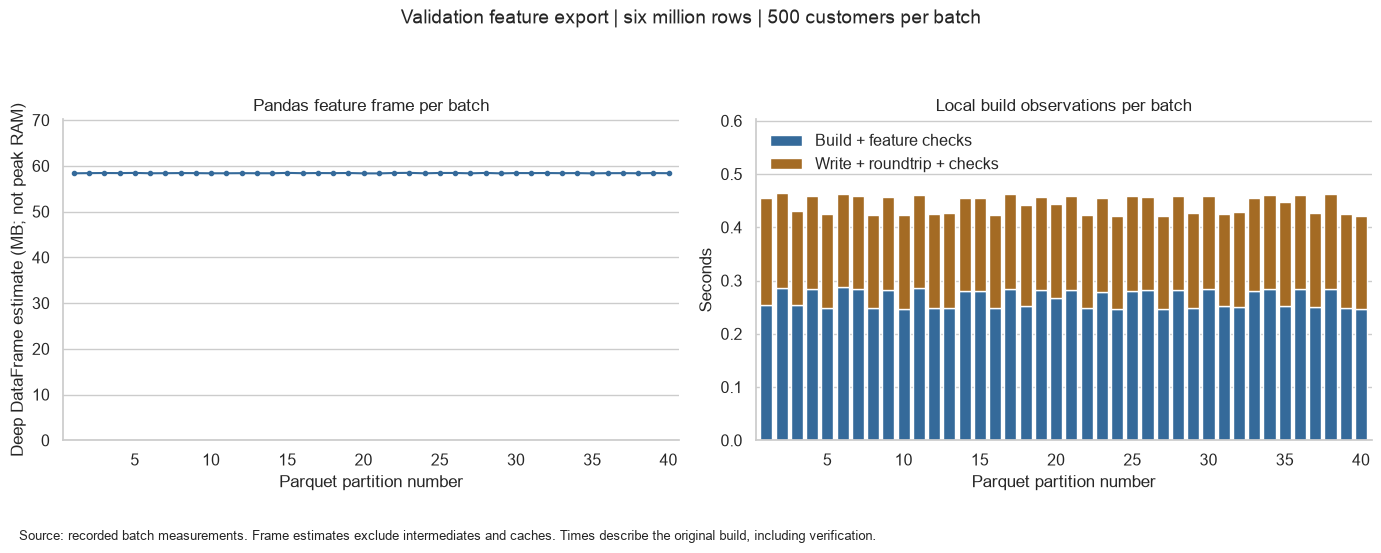

In [64]:
partition_numbers = range(1, len(partition_report) + 1)
fig_export, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot(partition_numbers, partition_report["dataframe_deep_mb"], marker=".", color="#356A9A")
axes[0].set_title("Pandas feature frame per batch")
axes[0].set_ylabel("Deep DataFrame estimate (MB; not peak RAM)")
axes[0].set_ylim(0, partition_report["dataframe_deep_mb"].max() * 1.2)
axes[1].bar(partition_numbers, partition_report["build_seconds"], label="Build + feature checks", color="#356A9A")
axes[1].bar(
    partition_numbers, partition_report["write_roundtrip_seconds"],
    bottom=partition_report["build_seconds"], label="Write + roundtrip + checks", color="#A46B24",
)
axes[1].set_title("Local build observations per batch")
axes[1].set_ylabel("Seconds")
axes[1].set_ylim(0, (partition_report["build_seconds"] + partition_report["write_roundtrip_seconds"]).max() * 1.3)
axes[1].legend(loc="upper left", frameon=False)
for ax in axes:
    ax.set_xlabel("Parquet partition number")
    ax.grid(axis="x", visible=False)
    ax.set_xlim(0.3, len(partition_report) + 0.7)
sns.despine(fig=fig_export)
fig_export.suptitle("Validation feature export | six million rows | 500 customers per batch", fontsize=14, y=0.99)
fig_export.tight_layout(rect=(0, 0.08, 1, 0.93))
fig_export.text(
    0.02, 0.025,
    "Source: recorded batch measurements. Frame estimates exclude intermediates and caches. "
    "Times describe the original build, including verification.", fontsize=9,
)
plt.show()

### Interpretation

Reference execution produced **6,000,000 rows for 20,000 customers**, in **40 partitions** of 150,000 rows. The schema has 22 columns: three prediction keys, two audit descriptors and seventeen numeric/boolean model features. The Parquet partitions total approximately **7.3 MiB**; repeated identifiers and feature values compress well. The largest feature DataFrame's deep-memory estimate was approximately **58.5 MiB**. This estimate excludes intermediates and caches and is not a process peak-RAM measurement.

Expected missingness is preserved: customer recency is absent in **2,799,900 rows (46.665%)**, exactly 9,333 cold-history customers times 300 candidates. Customer–article recency is absent in **5,901,863 rows (98.364%)**, and recent article rank in **17,895 rows (0.298%)**. All required feature values are present. Historical interaction count is positive for 98,137 pairs, while 98,125 pairs belong to the capped history retrieval list: an observed interaction and inclusion in the top-100 history source are different facts.

Every partition passed schema and exact value/null round-trip checks. Stored customer counts and missingness totals agree with the manifest. Additional independent checks matched 30,000 stored rows to the existing pilot, checked source flags for all 150,000 rows in another partition against the original retrieval lists, and matched the complete history-source count. A repeat call verified and reused the export without invoking the builder or rewriting its first partition. Five exporter unit tests and all existing tests passed together (**32 tests**).

The complete 64-code-cell notebook was executed sequentially in a fresh Python process with the project environment. The six new section 10 cells have no saved Jupyter outputs in this handoff: save the source, restart the project kernel, Run All, inspect and save. The standalone export PNG was rendered and visually inspected separately. Keep source-code snapshots and manifest provenance distinct from a future packaged release.

This export contains unlabelled validation-cutoff features. It is not a training dataset and no model, encoder, imputer or scaler has been fitted. Global source checks here use recorded source hashes and current sizes; generated artifact checksums and exact Parquet round trips are fresh checks.

## Next Milestone

Define earlier supervised prediction cutoffs and seven-day relevance labels with target windows ending no later than validation starts. Recompute history, popularity, candidates and features at each cutoff. Then consolidate remaining notebook functions, tests and documentation before model training. Local-test outcomes remain uninspected.

## Revision Links
- [Existing evaluation protocol](../docs/evaluation.md).
- [Data foundation notebook](01_data_foundation.ipynb): chronological evaluation windows and exclusive-end intervals.
- [Behavioral EDA notebook](02_behavioral_eda.ipynb): amount of history and leakage controls.
- [Working with Dates and Times in Python — Math with dates](</Users/oumar/Documents/Data science/Working with Dates and Times in Python/Chapter 1:4 - Dates and Calendars/2 - Math with dates.mp4>): local video located by title, not watched in this milestone.
- [Google Trends notebook](</Users/oumar/Downloads/Google Trends Data Viz (complete)/Google_Trends_and_Data_Visualisation_(complete).ipynb>): converting date strings to datetime values.
- [pandas Timedelta reference](https://pandas.pydata.org/docs/reference/api/pandas.Timedelta.html).
- [Sampling in Python — Sampling and point estimates](</Users/oumar/Documents/Data science/Advanced Data Analysis/II - Sampling in Python/Chapter 1:4 - Introduction to Sampling/1 - Sampling and point estimates.mp4>): revise source populations and samples.
- [Sampling in Python — Pseudo-random number generation](</Users/oumar/Documents/Data science/Advanced Data Analysis/II - Sampling in Python/Chapter 1:4 - Introduction to Sampling/3 - Pseudo-random number generation.mp4>): related reproducibility and seed concepts; the implementation here uses hashing instead of a pseudo-random generator.
- [Sampling in Python — Simple random and systematic sampling](</Users/oumar/Documents/Data science/Advanced Data Analysis/II - Sampling in Python/Chapter 2:4 - Sampling Methods/1 - Simple random and systematic sampling.mp4>): compare selection strategies. Video references were located by title, not watched for this milestone.
- [College major notebook](</Users/oumar/Downloads/Data_Exploration_Pandas_College_Major+%28complete%29/Data_Exploration_Pandas_College_Major_(complete).ipynb>): existing `sort_values()` followed by `head()` patterns.
- [Python hashlib documentation](https://docs.python.org/3/library/hashlib.html).
- [Joining Data with pandas — Filtering joins](</Users/oumar/Documents/Data science/Joining Data with pandas/Chapter 3 - Advanced Merging and Concatenating/Joining Data with pandas | Filtering joins.mp4>): related population-membership filtering; `.isin()` is used here.
- [Nobel Prize notebook](</Users/oumar/Downloads/Nobel+Prize+Analysis+Complete/Nobel_Prize_Analysis_(complete).ipynb>): `groupby()`, `value_counts()` and `merge()` patterns, reused here at customer–article and customer grains.
- [SQL — Grouping data](</Users/oumar/Documents/Data science/SQL/Intermediate SQL/Chapter 4:4 - Sorting and Grouping/2 - Grouping data.mp4>): aggregation grain and counts. Video references are located by title, not watched for this milestone.
- [Machine Learning for Business — Model performance measurement](</Users/oumar/Documents/Data science/Data scientist/Machine Learning for Business/Chapter 3:4 - Business requirements and model design/3 - Model performance measurement.mp4>): related choice of evaluation criteria. Located by title, not watched here; exact MAP/Recall conventions come from the project's evaluation document.
- [Evaluation strategy](../docs/evaluation.md): primary metric, denominators, eligibility and chronological protocol.
- [Behavioral EDA](02_behavioral_eda.ipynb), sections 4 (customer recency), 6 (customer–article history) and 8 (H3 repurchases and H4 history heterogeneity): modelling motivation, not proof of predictive benefit.
- [Working with Dates and Times in Python — Summarizing datetime data in Pandas](</Users/oumar/Documents/Data science/Working with Dates and Times in Python/Chapter 4:4 - Easy and Powerful | Dates and Times in Pandas/2 - Summarizing datetime data in Pandas.mp4>): related date aggregations. Located by title, not watched here.
- [Working with Categorical Data in Python — Grouping data by category in pandas](</Users/oumar/Documents/Data science/Working with Categorical Data in Python/Chapter 1 - Introduction to Categorical Data/3 - Grouping data by category in pandas.mp4>): related segment aggregation. Located by title, not watched here.
- [Joining Data with pandas — One-to-many relationships](</Users/oumar/Documents/Data science/Joining Data with pandas/Chapter 1 - Data Merging Basics/2 - One-to-many relationships.mp4>): related join cardinality; the article-metadata attachment here is many-to-one.
- [Joining Data with pandas — Verifying integrity](</Users/oumar/Documents/Data science/Joining Data with pandas/Chapter 3 - Advanced Merging and Concatenating/Joining Data with pandas | Verifying integrity.mp4>): related join and count reconciliation. Videos located by title, not watched here.
- [Behavioral EDA](02_behavioral_eda.ipynb), sections 6 and 8: observed product-group preferences and H2.
- [Joining Data with pandas — Filtering joins](</Users/oumar/Documents/Data science/Joining Data with pandas/Chapter 3 - Advanced Merging and Concatenating/Joining Data with pandas | Filtering joins.mp4>): related membership/intersection reasoning. Video located by title, not watched here.
- [College major notebook](</Users/oumar/Downloads/Data_Exploration_Pandas_College_Major+%28complete%29/Data_Exploration_Pandas_College_Major_(complete).ipynb>): `sort_values()` followed by `head()` patterns, reused when bounding retrieval lists.
- [Evaluation strategy](../docs/evaluation.md): candidate coverage and inclusion of targets absent from the generated set.

- [Andrew Ng — Unsupervised Learning, Recommenders, Reinforcement Learning](https://www.coursera.org/learn/unsupervised-learning-recommenders-reinforcement-learning), week 2 (Recommender systems), video **Recommending from a large catalogue**: closest revision topic for separating candidate retrieval from ranking. The official syllabus and video title were verified; the video was not watched for this milestone.
- [DataCamp — Preprocessing for machine learning in Python — Feature engineering](</Users/oumar/Documents/Data science/Data scientist/Preprocessing for machine learning in Python/Chapter 3:5 - Feature Engineering/1 - Feature engineering.mp4>).
- [DataCamp — Engineering numerical features](</Users/oumar/Documents/Data science/Data scientist/Preprocessing for machine learning in Python/Chapter 3:5 - Feature Engineering/3 - Engineering numerical features.mp4>): related counts, shares and elapsed-time features.
- [DataCamp — Handling missing data](</Users/oumar/Documents/Data science/Machine Learning/I - Supervised Learning with scikit-learn/Chapter 4:4 - Preprocessing and Pipelines/2 - Handling missing data.mp4>): related missing-value semantics; no statistical imputer is fitted in this pilot.
- [College major notebook](</Users/oumar/Downloads/Data_Exploration_Pandas_College_Major+%28complete%29/Data_Exploration_Pandas_College_Major_(complete).ipynb>): derived numeric columns. Course videos located by title, not watched in this milestone.
- [Python Toolbox — Using Python generators for streaming data](</Users/oumar/Documents/Data science/Python Toolbox/Chapter 3:3 - Bringing it all together!/2 - Using Python generators for streaming data.mp4>): related bounded-memory processing; this exporter uses an explicit customer-batch loop.
- [Writing Functions in Python — Using context managers](</Users/oumar/Documents/Data science/Writing Functions in Python/Chapter 2:4 - Context managers/1 - Using context managers.mp4>): related automatic connection and temporary-directory cleanup. Videos located by title, not watched here.
- [SQL — Grouping data](</Users/oumar/Documents/Data science/SQL/Intermediate SQL/Chapter 4:4 - Sorting and Grouping/2 - Grouping data.mp4>): aggregate validation of counts without loading all feature rows into pandas.
